# PETadex catalytic-core clustering (v260701): experiment and results

Hierarchical clustering of every complete catalytic core in PETadex into **90 / 60 / 30 % identity** centroids,
run on `watson` with DIAMOND 2.2.4 using Benjamin Buchfink's `unid/` pipeline over **15 CATH domains**.
Figures: `figures/` (PNG + SVG); figure code: `analysis/`; pipeline code: `pipeline/`; input tables: `data/` (not in the repo). Caveats and open issues: [`docs/caveats.md`](docs/caveats.md).

*In the project Slack thread this run is the end-to-end replication of Benjamin's v1.1 settings (folder `run2/`). To avoid
confusion with the thread's "Run 1 / Run 2", this notebook calls it **v2**.*

## 1. What we are trying to answer

| # | Question | Section |
|---|---|---|
| 1 | Is the result valid (every enzyme in one cluster, one centroid per cluster, exact nesting)? | 3 |
| 2 | What does the clustering produce (cores → 90 → 60 → 30 % centroids)? | 4.1 |
| 3 | How many centroids at each level come from PAZy, nr and Logan? | 4.2 |
| 4 | What is the CATH-domain composition of the clusters? | 4.3, 4.4 |
| 5 | How many singleton clusters are there, and how does that compare with v1.1? | 5 |
| 6 | Who are the singletons? | 6.1, 6.2 |
| 7 | Does the fragmented nature of Logan sequences make them harder to cluster? | 6.3 |

## 2. Input and method

### Input
Thomas Quigley's per-component catalytic-domain FASTAs (`petadex.v260701/dataset_generation/7_petadex_clustering`).
Each record is the HMM-hit range of a complete catalytic hit (i-evalue < 1e-5). Header:
`>{id}|{hmm}|{evalue}|{start}|{end}|{component}`. Preflight validated every record (length = hit range, no duplicate IDs,
no empty sequences).

In [1]:
import os, re, pandas as pd
from IPython.display import Image, display
pd.options.display.float_format = '{:,.1f}'.format; pd.options.display.max_columns = 30
ROOT = os.getcwd()
FIGS = os.path.join(ROOT, 'figures'); DATA = os.path.join(ROOT, 'data')
S = pd.read_csv(os.path.join(DATA, 'cluster_stats.tsv'), sep='\t')
V11 = pd.read_csv(os.path.join(DATA, 'v11_reference.tsv'), sep='\t').set_index('level')
LV = {'L90': '90%', 'L60': '60%', 'L30': '30%'}
def show(name, width=820): display(Image(filename=os.path.join(FIGS, name + '.png'), width=width))
inp = pd.read_csv(os.path.join(DATA, 'counts_L90.tsv'), sep='\t', header=None, names=['domain', 'input', 'rows', 'members', 'clusters', 'reps'])
total = int(inp['input'].sum())
pd.DataFrame({'source': ['PAZy (PL)', 'nr (NR)', 'Logan (LG)', 'Total clustered'],
              'cores': [486, 6_764_617, 291_922_243, total]}).style.hide(axis='index').format('{:,}', subset=['cores'])

source,cores
PAZy (PL),486
nr (NR),"6,764,617"
Logan (LG),"291,922,243"
Total clustered,"298,687,346"


#### Where the 486 Plasticome (PAZy) sequences come from

| Step | Sequences | Source |
|---|---:|---|
| Union of PAZy v1.1 and the v260701 PAZy pull | 609 (PL1–PL609) | `data/plasticome.v2 (5).xlsx`, sheet `plasticome-v1-v260701-union` (397 v260701 only, 136 v1.1 only, 76 both) |
| One per distinct amino-acid sequence | 493 | sheet `plasticome-union.non-redundant`; Thomas's `petadex-plasticome.v260701.100pid-centroids.fastaa` |
| Any PETadex HMM hit | 492 | PL56 has no hit |
| Complete catalytic hit, e-value < 1e-5 | 487 | PL62, PL115, PL119, PL120 and PL456 have only incomplete hits |
| Best hit per protein, kept only if complete | **486** | one core per protein; PL559 drops out here (see caveats) |

### Method (per CATH domain, per level)
Sources are processed in priority order **PAZy → nr → Logan**, so a centroid always comes from the highest-priority source in
its cluster. A member joins a centroid when it reaches the level's identity with **≥ 90 % of the member covered** by the alignment.
Step-by-step reference with all settings: [`docs/unid_pipeline_upstream.md`](docs/unid_pipeline_upstream.md).

| Step | What happens |
|---|---|
| 1 | Cluster the PAZy cores (all-vs-all alignment, greedy vertex cover) |
| 2 | Map nr cores onto the PAZy centroids |
| 3 | Cluster the remaining nr cores (`deepclust`) |
| 4 | Map all Logan cores onto the PAZy + nr centroids (fast linear search) |
| 5–6 | Split the Logan leftovers into chunks and map them again, more sensitively |
| 7 | Collect the still-unassigned Logan cores |
| 8 | Cluster them among themselves (`deepclust`) |
| 9 | Merge all assignments into `<domain>.all.tsv` (`centroid<TAB>member`) |
| 10 | Extract the centroid sequences as the next level's input |

| Level | Input | Identity | step 3 | step 6 sensitivity | step 8 |
|---|---|---|---|---|---|
| 90 % | all cores | 90 | default | `--fast` | `faster_lin fast_lin shapes-30x10_lin` |
| 60 % | 90 % centroids | 60 | default | default | `faster_lin default` |
| 30 % | 60 % centroids | 30 | ultra-sensitive | `--ultra-sensitive` | ultra-sensitive |

Each level clusters the previous level's centroids, so nesting is exact by construction.

### Execution on watson
watson has 480 hardware threads and 754 GB RAM. The run started **Sat Oct 24, 7:04 PM EDT** and finished **Wed Nov 4, 2:33 PM EST**:
10 days 20.5 hours of wall time. That includes pauses for Thomas's DIAMOND work and the k2-circ rod screen, about a day lost to a
stalled /dev/shm guard, and the last days on half the server.

Compute, as **thread-hours** (DIAMOND's thread count × run time for every run whose output was kept; an upper bound on CPU-hours,
and it excludes runs that were killed and redone). Per-run data: `data/compute/diamond_runs.tsv`.

In [2]:
runs = pd.read_csv(os.path.join(DATA, 'compute', 'diamond_runs.tsv'), sep='\t', header=None,
                   names=['level', 'domain', 'step', 'log', 'threads', 'seconds'])
runs['thread_hours'] = runs.threads * runs.seconds / 3600
tot_h = runs.thread_hours.sum()
print(f"total {tot_h:,.0f} thread-hours = {tot_h / 480:,.0f} h ({tot_h / 480 / 24:.1f} days) on all 480 threads if perfectly packed")
print(f"amidase-signature alone: {runs[runs.domain == 'amidase-signature'].thread_hours.sum():,.0f} thread-hours")

total 33,195 thread-hours = 69 h (2.9 days) on all 480 threads if perfectly packed
amidase-signature alone: 18,111 thread-hours


About **33,200 thread-hours**. Three quarters is step 6 (re-mapping Logan leftovers) at the 90 % level, and amidase-signature
alone is 55 % (its 41 Logan chunks took about 15 hours each). On a dedicated watson the run could not finish in less than
~69 hours (2.9 days, all threads busy all the time); in practice it would take longer, because the large `deepclust` steps run
one at a time to keep their temporary files within the disk.

## 3. Validity: is each enzyme in exactly one cluster?

Checked on the finished `<domain>.all.tsv` files across all 15 domains (`analysis/uniqueness_check.sh`).

In [3]:
rep = {}
for L in ['L90', 'L60', 'L30']:
    txt = open(os.path.join(DATA, 'uniqueness', f'{L}.report')).read()
    g = lambda pat: int(re.search(pat + r'\s+(\d+)', txt).group(1))
    rep[LV[L]] = {'member rows': g(r'member rows'), 'distinct proteins': g(r'distinct proteins'),
                  'proteins in >1 row': g(r'proteins in >1 row'), 'distinct centroids': g(r'distinct centroids \(rep column\)'),
                  'centroids without a self row': g(r'centroids without a self row'),
                  'proteins that are the centroid of >1 cluster': g(r'proteins that are the centroid of >1 cluster')}
display(pd.DataFrame(rep).style.format('{:,}'))
nest = open(os.path.join(DATA, 'uniqueness', 'nesting.report')).read().strip().splitlines()
print(f"nesting: {sum(l.endswith(' OK') for l in nest)} of {len(nest)} domain-level pairs OK")

,90%,60%,30%
member rows,"298,687,346","32,022,716","3,230,662"
distinct proteins,"298,687,346","32,022,716","3,230,662"
proteins in >1 row,0,0,0
distinct centroids,"32,022,716","3,230,662","65,769"
centroids without a self row,0,0,0
proteins that are the centroid of >1 cluster,0,0,0


nesting: 30 of 30 domain-level pairs OK


Every core appears in exactly one cluster at every level, every centroid is a member of its own cluster, no protein is the
centroid of more than one cluster, and each level's members are exactly the level above's centroids in all 15 domains.

## 4. Results
### 4.1 The cascade

In [4]:
tot = S.groupby('level')[['clusters', 'singletons', 'members', 'PL', 'NR', 'LG']].sum().loc[['L90', 'L60', 'L30']]
casc = pd.DataFrame({'input to this level': tot['members'], 'clusters': tot['clusters']})
casc['reduction (x)'] = casc['input to this level'] / casc['clusters']
casc.index = [LV[i] for i in casc.index]; casc.style.format({'clusters': '{:,}', 'input to this level': '{:,}', 'reduction (x)': '{:.1f}'})

,input to this level,clusters,reduction (x)
90%,"298,687,346","32,022,716",9.3
60%,"32,022,716","3,230,662",9.9
30%,"3,230,662","65,769",49.1


#### Cluster size distribution
Size is the number of direct members: cores at 90 %, 90 % centroids at 60 %, 60 % centroids at 30 %. Bins after the first are 2–9, then decades
(10–99, 100–999, ...), so wider bins cover more sizes.

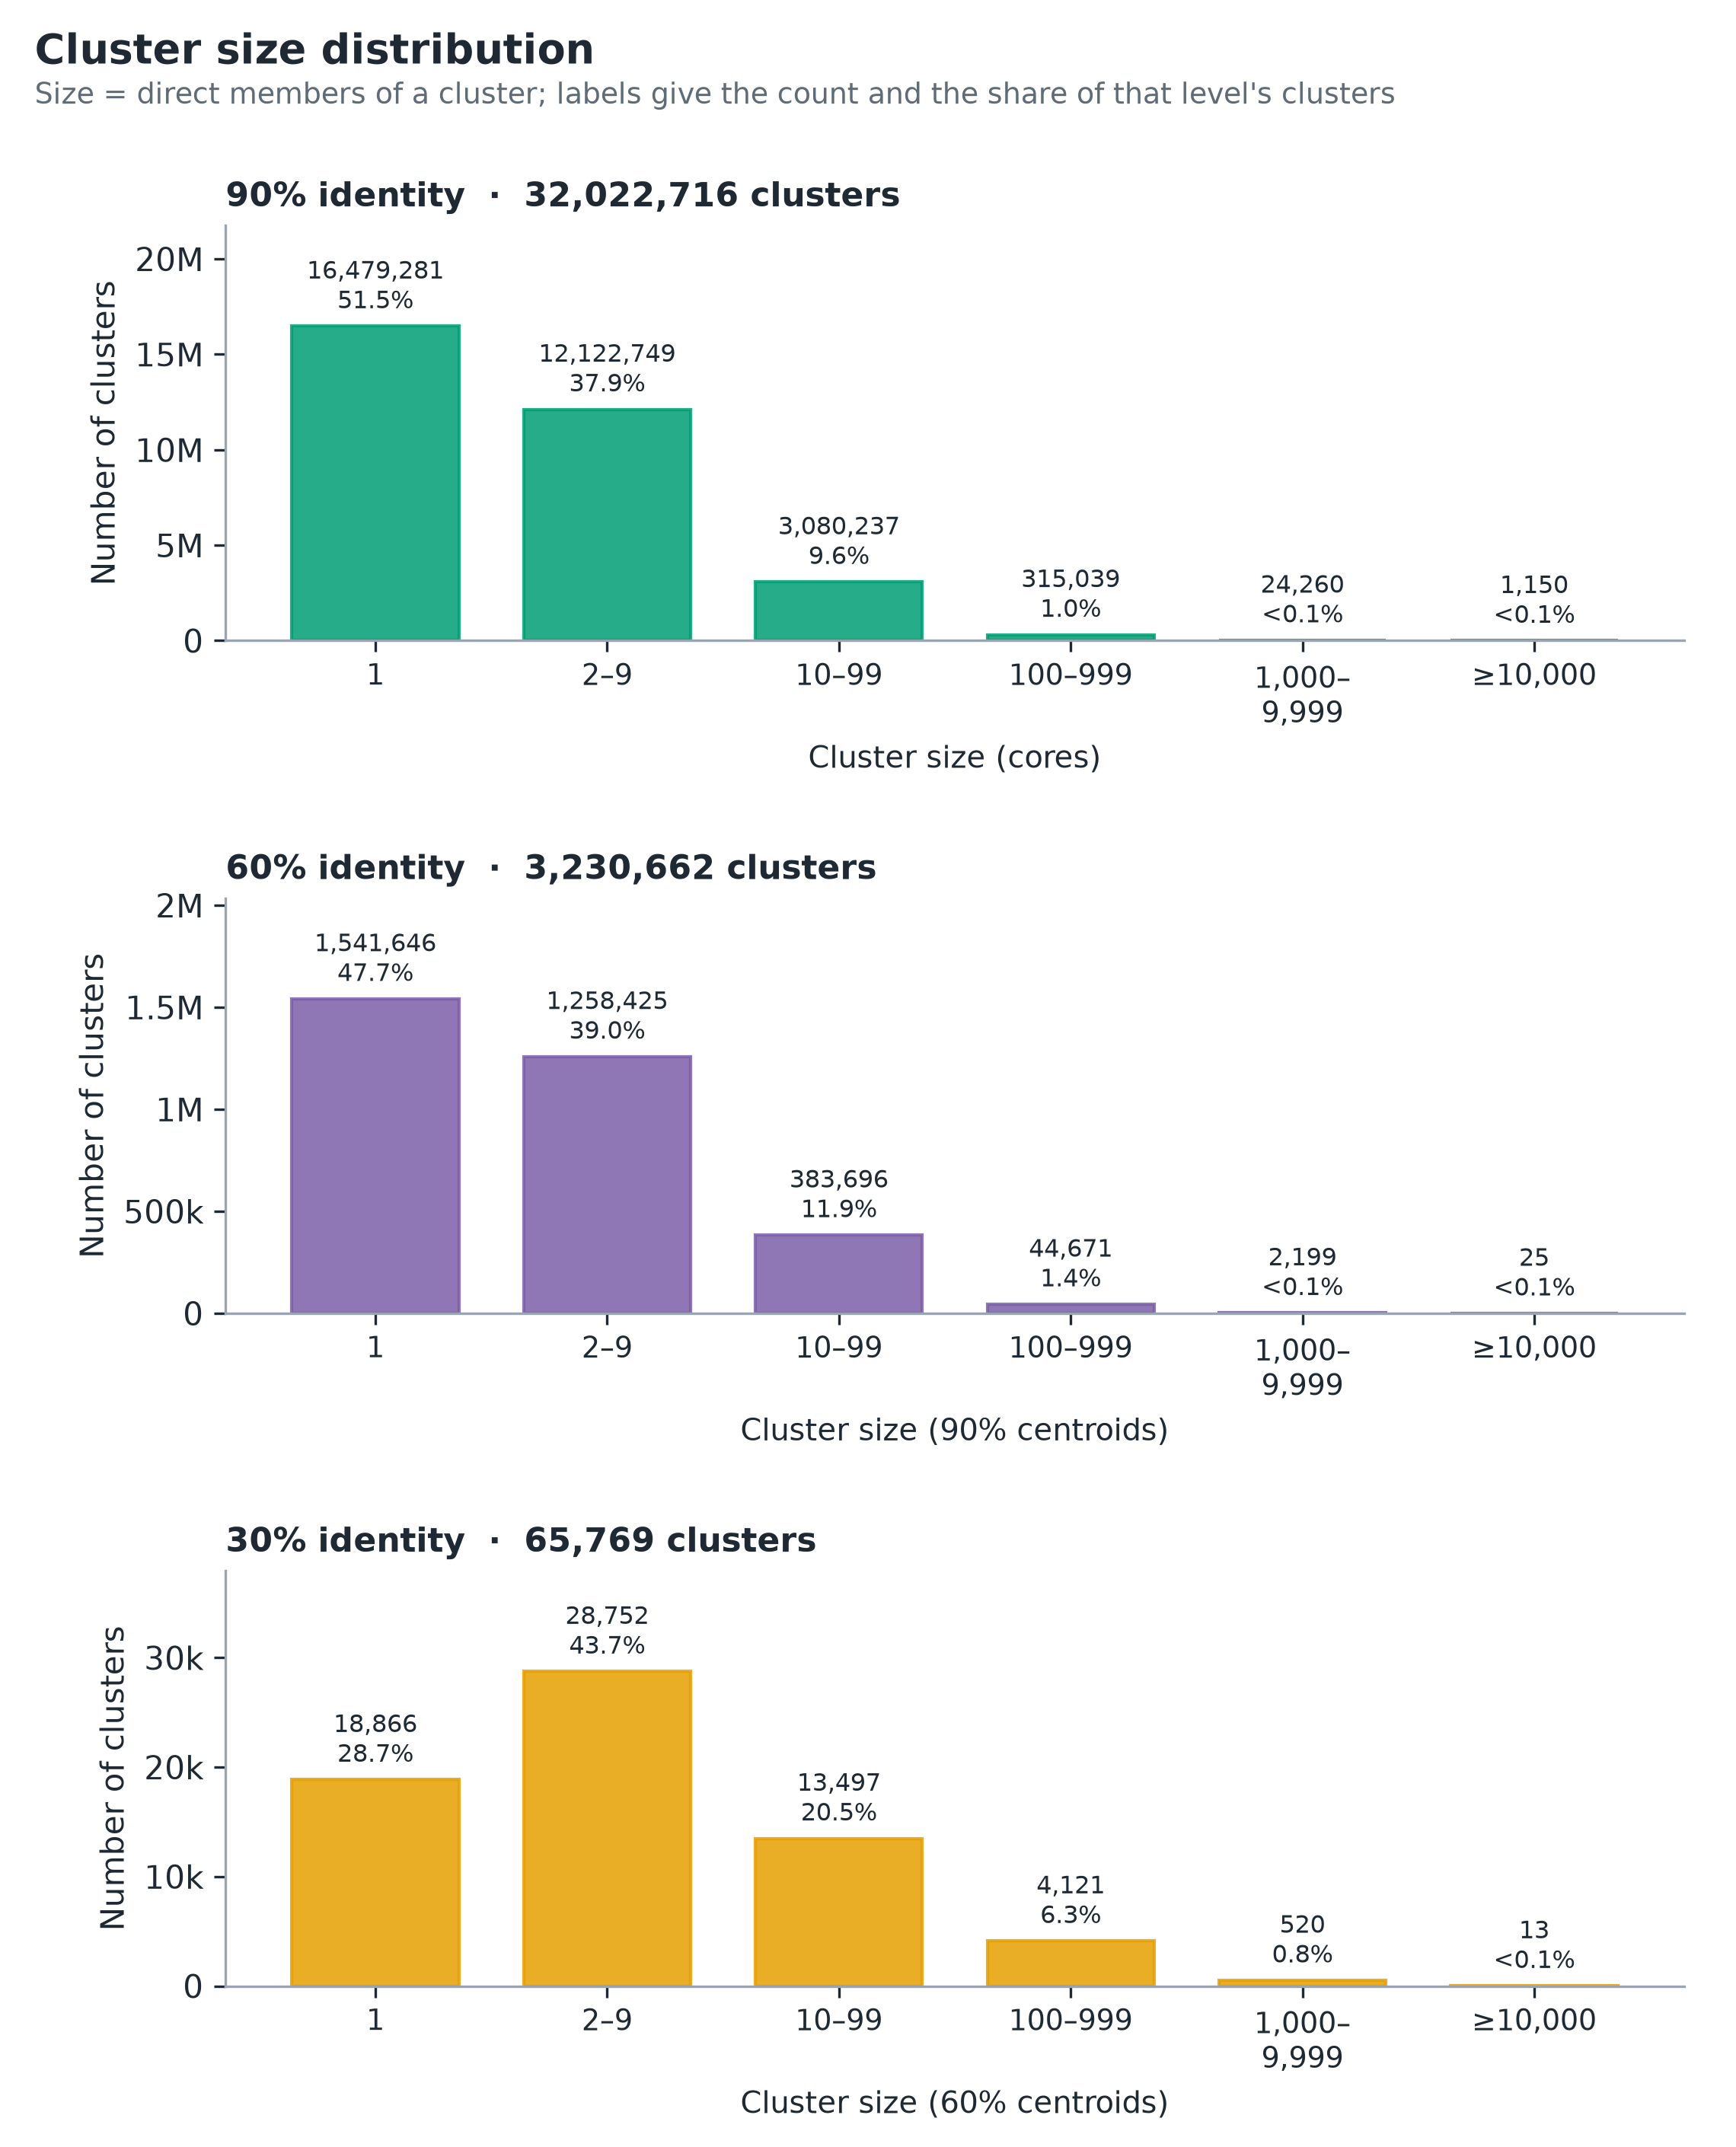

In [5]:
show('fig4_cluster_size_distribution', 640)

In [6]:
sz = pd.read_csv(os.path.join(DATA, 'diagnostics', 'cluster_size_binned.tsv'), sep='\t')
sz['level'] = sz['level'].map(LV)
t = sz.pivot(index='size', columns='level', values='pct_members').loc[sz['size'].unique(), ['90%', '60%', '30%']]
t.columns = [f'% of {c} members' for c in t.columns]; t.style.format('{:.1f}')

,% of 90% members,% of 60% members,% of 30% members
size,,,
1,5.5,4.8,0.6
2–9,14.7,14.5,3.5
10–99,26.5,32.1,12.9
100–999,26.0,33.6,37.5
"1,000–9,999",19.9,13.8,38.8
"≥10,000",7.4,1.2,6.7


Most clusters are small but most sequence sits in large clusters: half of the 90 % clusters are singletons, yet 53 % of all cores are in
90 % clusters of 100 or more; at 30 %, 83 % of the 60 % centroids are in superfamilies of 100 or more.

### 4.2 Which database owns the centroids?

In [7]:
src = tot[['PL', 'NR', 'LG']].rename(columns={'PL': 'PAZy', 'NR': 'nr', 'LG': 'Logan'}); src.index = [LV[i] for i in src.index]
display(src.style.format('{:,}'))
display((src.div(src.sum(axis=1), axis=0) * 100).style.format('{:.3g}%'))

,PAZy,nr,Logan
90%,360,"2,359,241","29,663,115"
60%,204,"414,325","2,816,133"
30%,76,"7,991","57,702"


,PAZy,nr,Logan
90%,0.00112%,7.37%,92.6%
60%,0.00631%,12.8%,87.2%
30%,0.116%,12.2%,87.7%


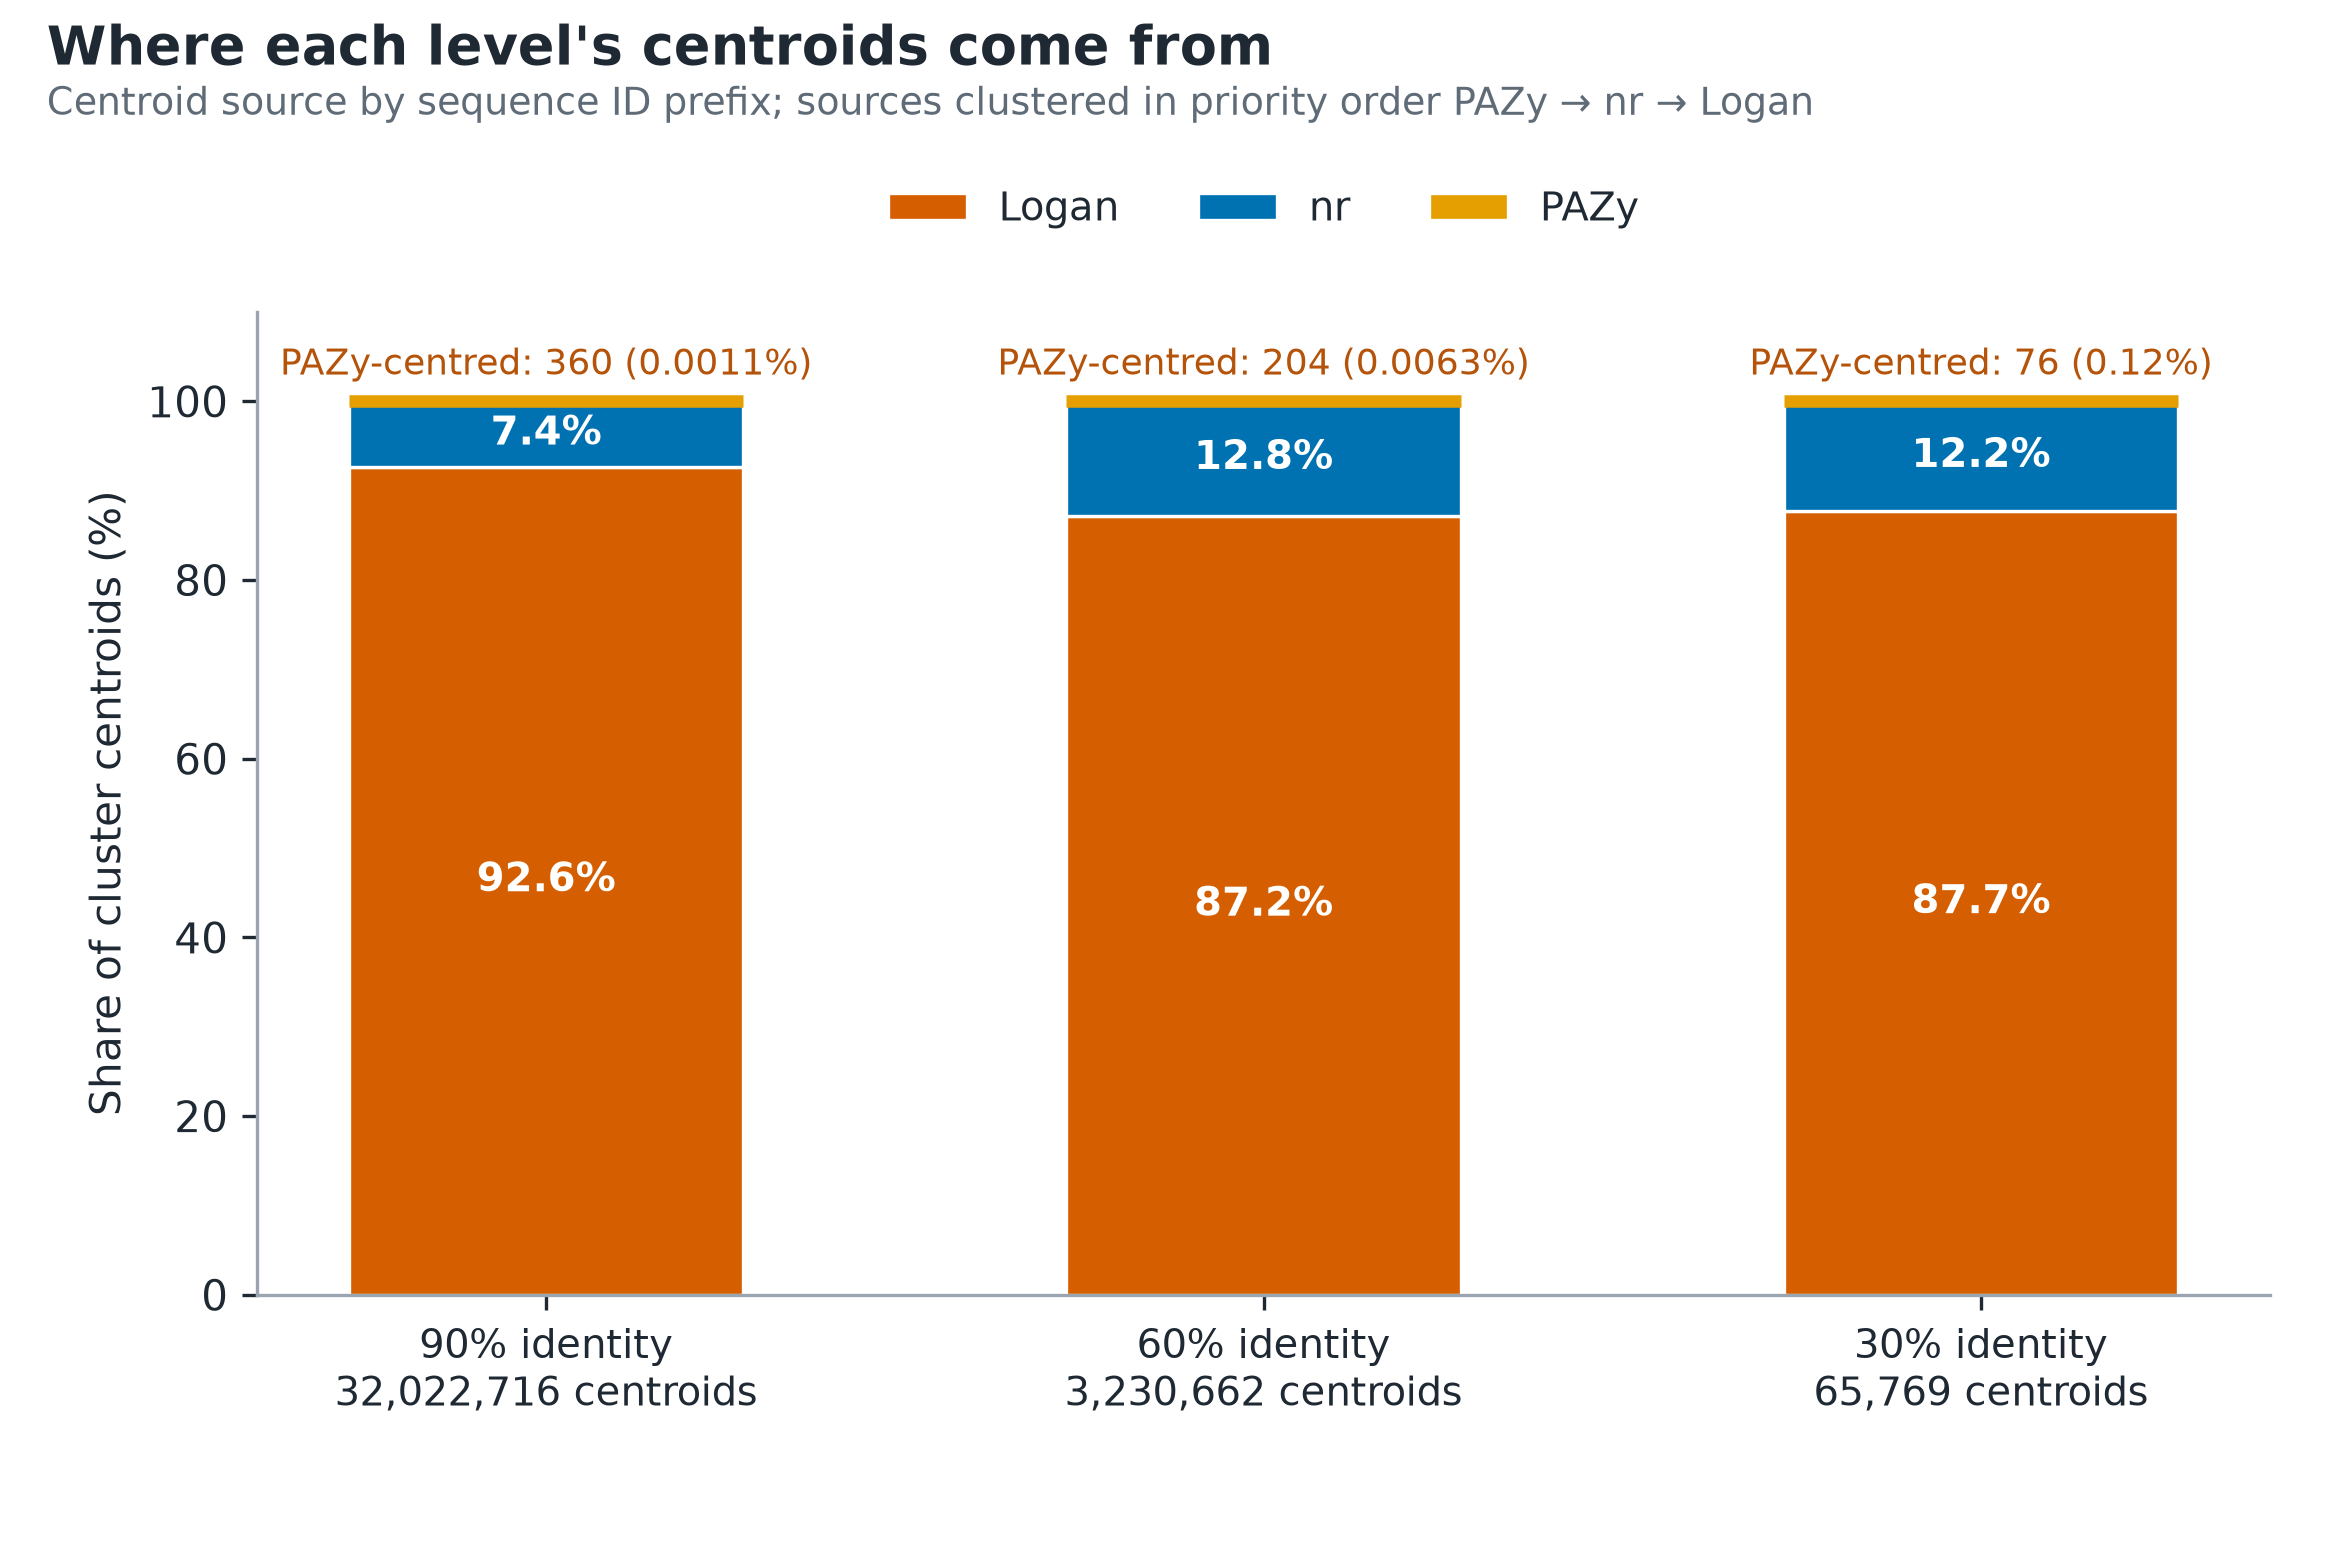

In [8]:
show('fig2_source_of_centroids', 760)

#### Figure 1: what Logan adds
Because PAZy and nr are clustered before any Logan sequence is involved (at every level), clustering PAZy + nr alone gives exactly
the PAZy- and nr-centred superfamilies. Every Logan-centred superfamily therefore contains only Logan sequences.

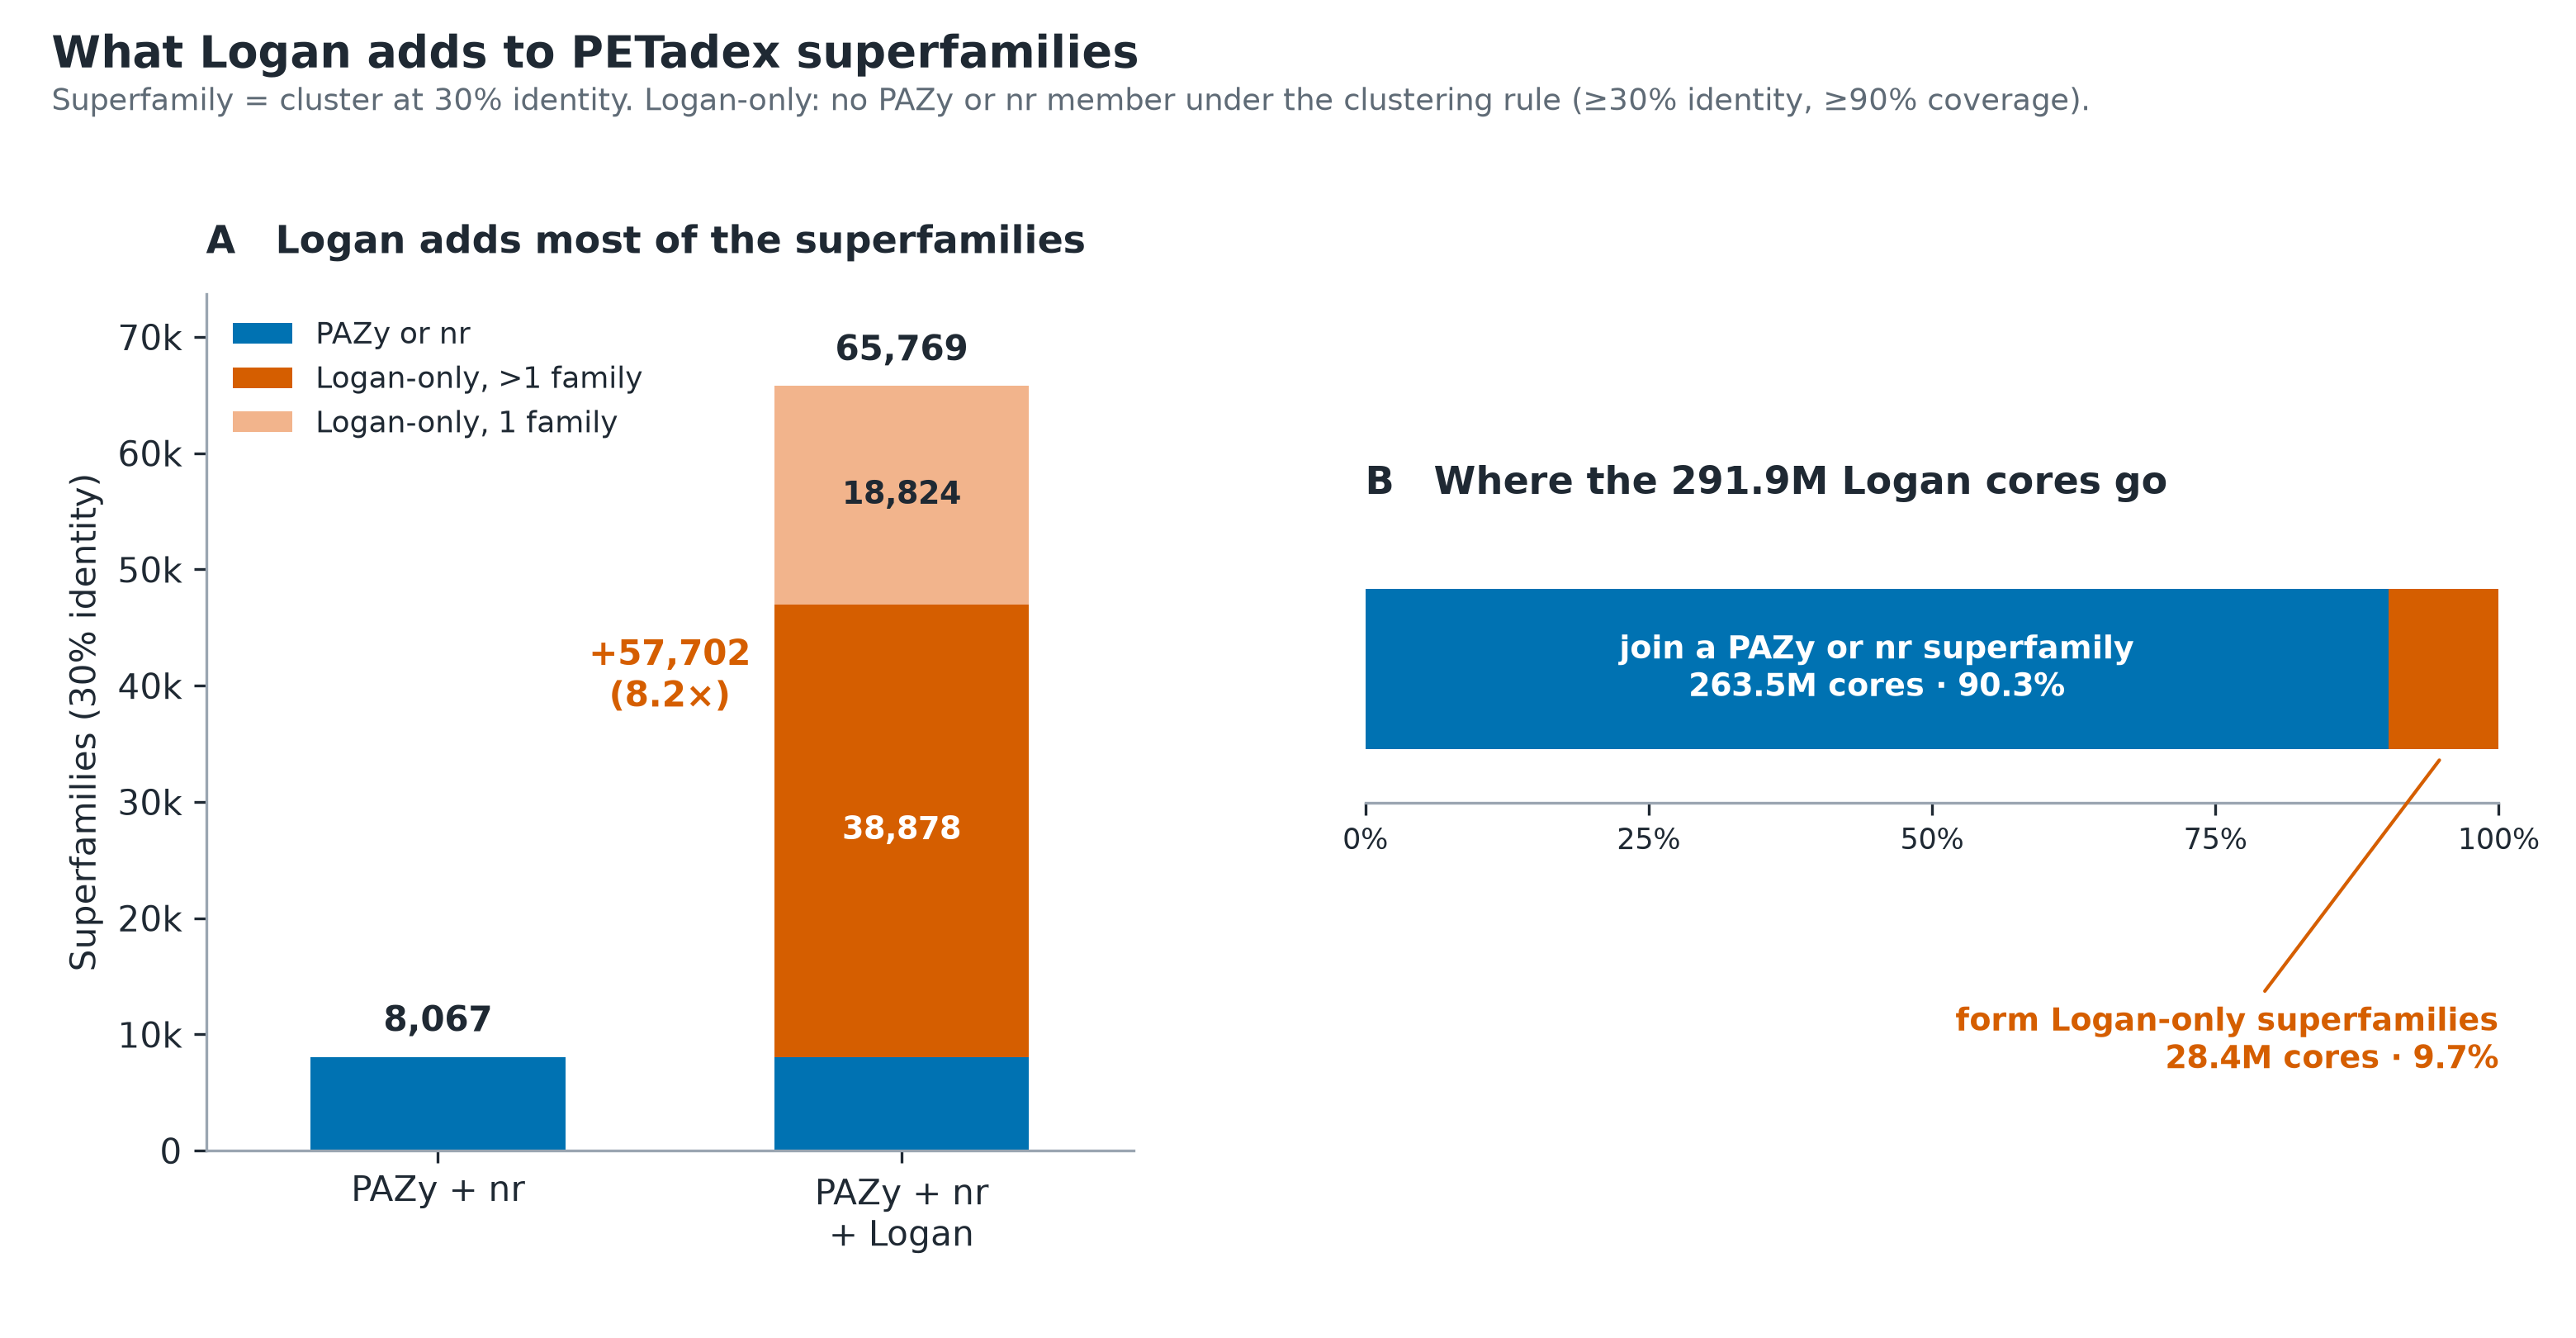

In [9]:
show('fig1_logan_adds', 900)

In [10]:
f1 = pd.read_csv(os.path.join(DATA, 'figure1_logan_adds.tsv'), sep='\t').T.rename(columns={0: 'value'})
f1.index = ['superfamilies from PAZy + nr', 'Logan-only superfamilies, >1 family', 'Logan-only superfamilies, 1 family', 'superfamilies in total',
            'Logan cores', 'Logan cores in a PAZy or nr superfamily', 'Logan cores in Logan-only superfamilies']
f1.style.format('{:,}')

,value
superfamilies from PAZy + nr,"8,067"
"Logan-only superfamilies, >1 family","38,878"
"Logan-only superfamilies, 1 family","18,824"
superfamilies in total,"65,769"
Logan cores,"291,922,243"
Logan cores in a PAZy or nr superfamily,"263,485,722"
Logan cores in Logan-only superfamilies,"28,436,521"


- **Logan adds 57,702 superfamilies** to the 8,067 that PAZy + nr give on their own (8.2× as many). 38,878 of them contain more than one
  60 % family; 18,824 are a single 60 % family (the singletons, often short fragments; section 6).
- **Most Logan sequences fill out known superfamilies:** 263.5 M of the 291.9 M Logan cores (90.3 %) join a superfamily that has a PAZy or nr
  member; 28.4 M (9.7 %) form the Logan-only superfamilies.
- "Logan-only" means no PAZy or nr member under the clustering rule (≥ 30 % identity, ≥ 90 % of the member covered), not that no nr
  sequence aligns to it.
- The 76 superfamilies containing a PAZy enzyme hold 47.3 M cores (15.8 % of all cores), but only 6.6 % of the distinct 60 % families.

### 4.3 Domain composition

In [11]:
comp = S.pivot(index='domain', columns='level', values='clusters')[['L90', 'L60', 'L30']]
share = (comp / comp.sum() * 100).sort_values('L90', ascending=False)
share.columns = [LV[c] + ' share (%)' for c in share.columns]
pd.concat([comp.loc[share.index].rename(columns=LV), share], axis=1).style.format({**{c: '{:,}' for c in LV.values()}, **{c: '{:.1f}' for c in share.columns}})

,90%,60%,30%,90% share (%),60% share (%),30% share (%)
domain,,,,,,
abhydrolase,"14,798,413","1,524,968","28,379",46.2,47.2,43.1
cytochrome-p450,"4,907,992","361,128","6,627",15.3,11.2,10.1
betalactamase,"3,851,379","351,840","5,295",12.0,10.9,8.1
amidase-signature,"1,863,544","92,757",667,5.8,2.9,1.0
peptidase-s8-s53,"1,725,242","298,501","6,135",5.4,9.2,9.3
metallo-phosphatase,"1,282,086","120,628","1,120",4.0,3.7,1.7
trypsin-like,"1,034,752","300,558","13,186",3.2,9.3,20.0
cupredoxins,"899,455","44,402","1,065",2.8,1.4,1.6
d-ala-esterase,"646,508","20,604",178,2.0,0.6,0.3


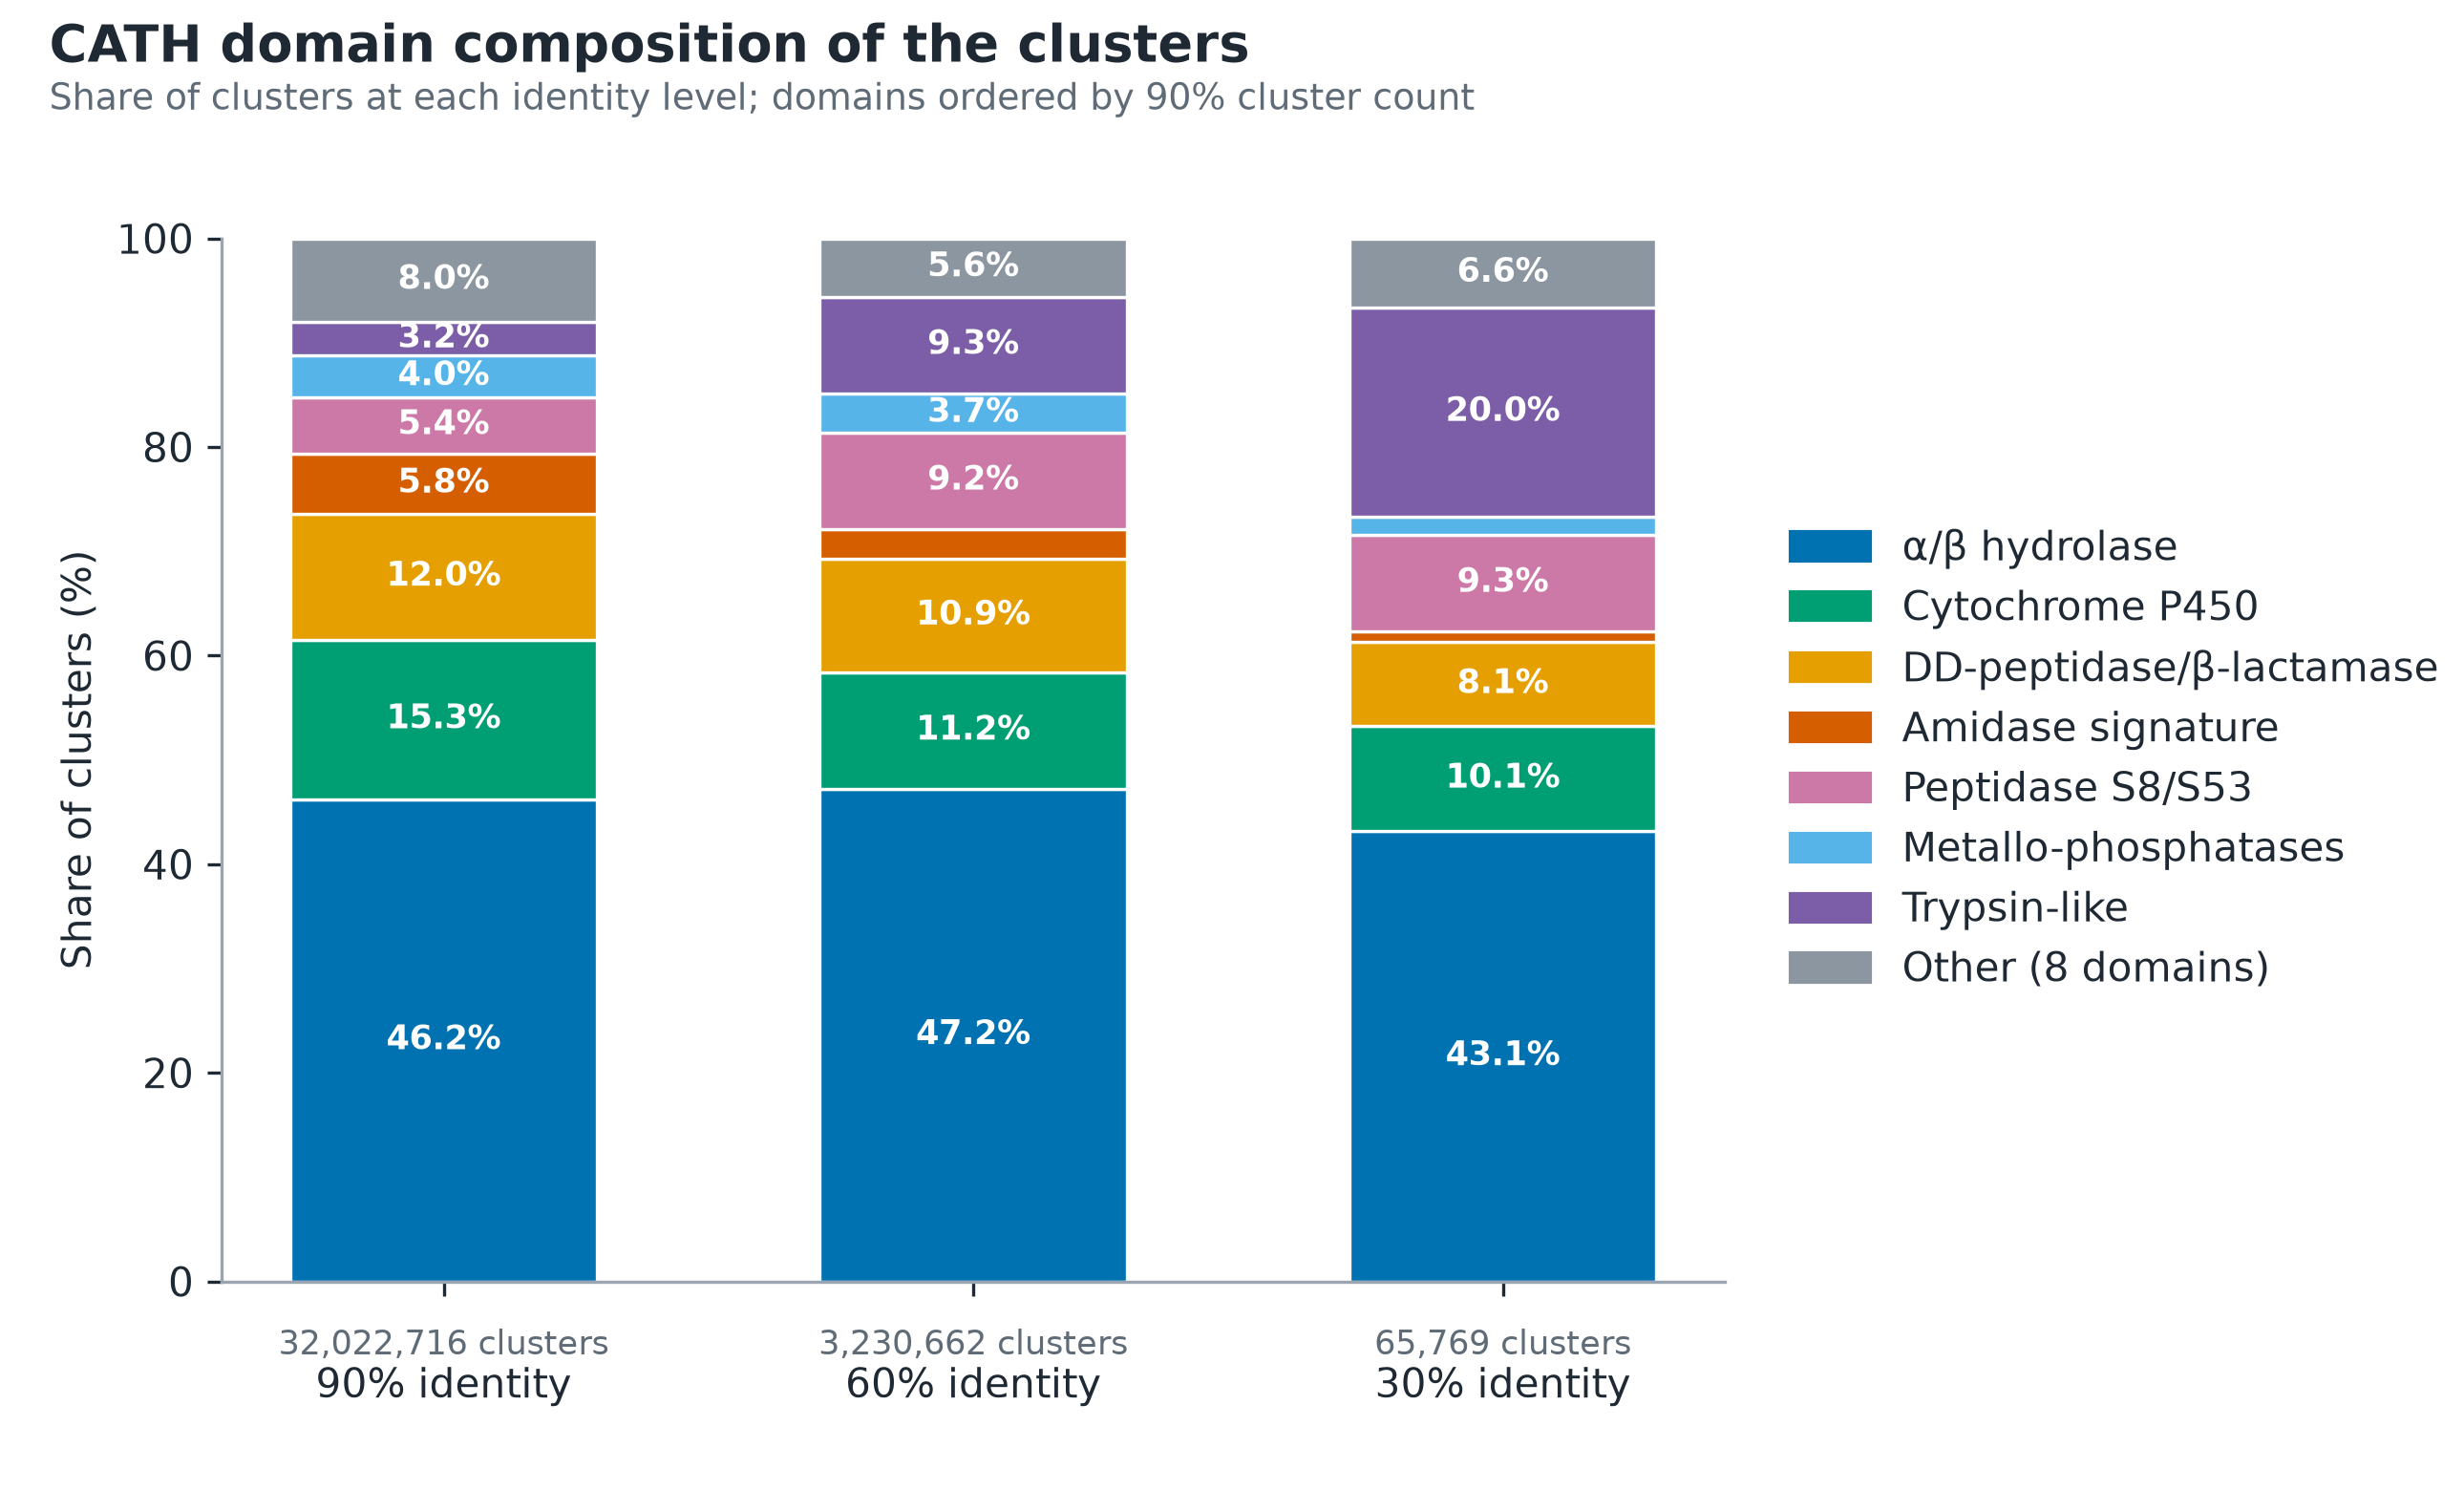

In [12]:
show('fig3_domain_composition', 860)

α/β hydrolases are about half of the clusters at every level, and most large domains lose share toward 30 %. The exception is
**trypsin-like: 3.2 % of the 90 % clusters but 20.0 % of the 30 % superfamilies (13,186), second only to α/β hydrolases.** We
simply find a great many trypsin superfamilies; the reason is not known.

### 4.4 Per-domain cascade

In [13]:
pd_ = comp.copy(); pd_['90→30 reduction (x)'] = pd_['L90'] / pd_['L30']
pd_ = pd_.sort_values('L90', ascending=False); pd_.columns = ['90%', '60%', '30%', '90→30 reduction (x)']
pd_.style.format({'90%': '{:,}', '60%': '{:,}', '30%': '{:,}', '90→30 reduction (x)': '{:,.0f}'})

,90%,60%,30%,90→30 reduction (x)
domain,,,,
abhydrolase,"14,798,413","1,524,968","28,379",521
cytochrome-p450,"4,907,992","361,128","6,627",741
betalactamase,"3,851,379","351,840","5,295",727
amidase-signature,"1,863,544","92,757",667,"2,794"
peptidase-s8-s53,"1,725,242","298,501","6,135",281
metallo-phosphatase,"1,282,086","120,628","1,120","1,145"
trypsin-like,"1,034,752","300,558","13,186",78
cupredoxins,"899,455","44,402","1,065",845
d-ala-esterase,"646,508","20,604",178,"3,632"


## 5. Singleton clusters, and comparison with v1.1

In [14]:
rows = []
for L in ['L90', 'L60', 'L30']:
    n, s = int(tot.loc[L, 'clusters']), int(tot.loc[L, 'singletons']); n1, s1 = int(V11.loc[L, 'clusters']), int(V11.loc[L, 'singletons'])
    rows.append({'level': LV[L], 'v2 clusters': n, 'v2 singletons': s, 'v2 singleton %': s / n * 100,
                 'v1.1 clusters': n1, 'v1.1 singletons': s1, 'v1.1 singleton %': s1 / n1 * 100})
pd.DataFrame(rows).set_index('level').style.format({'v2 clusters': '{:,}', 'v2 singletons': '{:,}', 'v1.1 clusters': '{:,}', 'v1.1 singletons': '{:,}',
                                                     'v2 singleton %': '{:.1f}', 'v1.1 singleton %': '{:.1f}'})

,v2 clusters,v2 singletons,v2 singleton %,v1.1 clusters,v1.1 singletons,v1.1 singleton %
level,,,,,,
90%,"32,022,716","16,479,281",51.5,"18,172,960","9,169,319",50.5
60%,"3,230,662","1,541,646",47.7,"1,814,296","571,803",31.5
30%,"65,769","18,866",28.7,"22,235","2,940",13.2


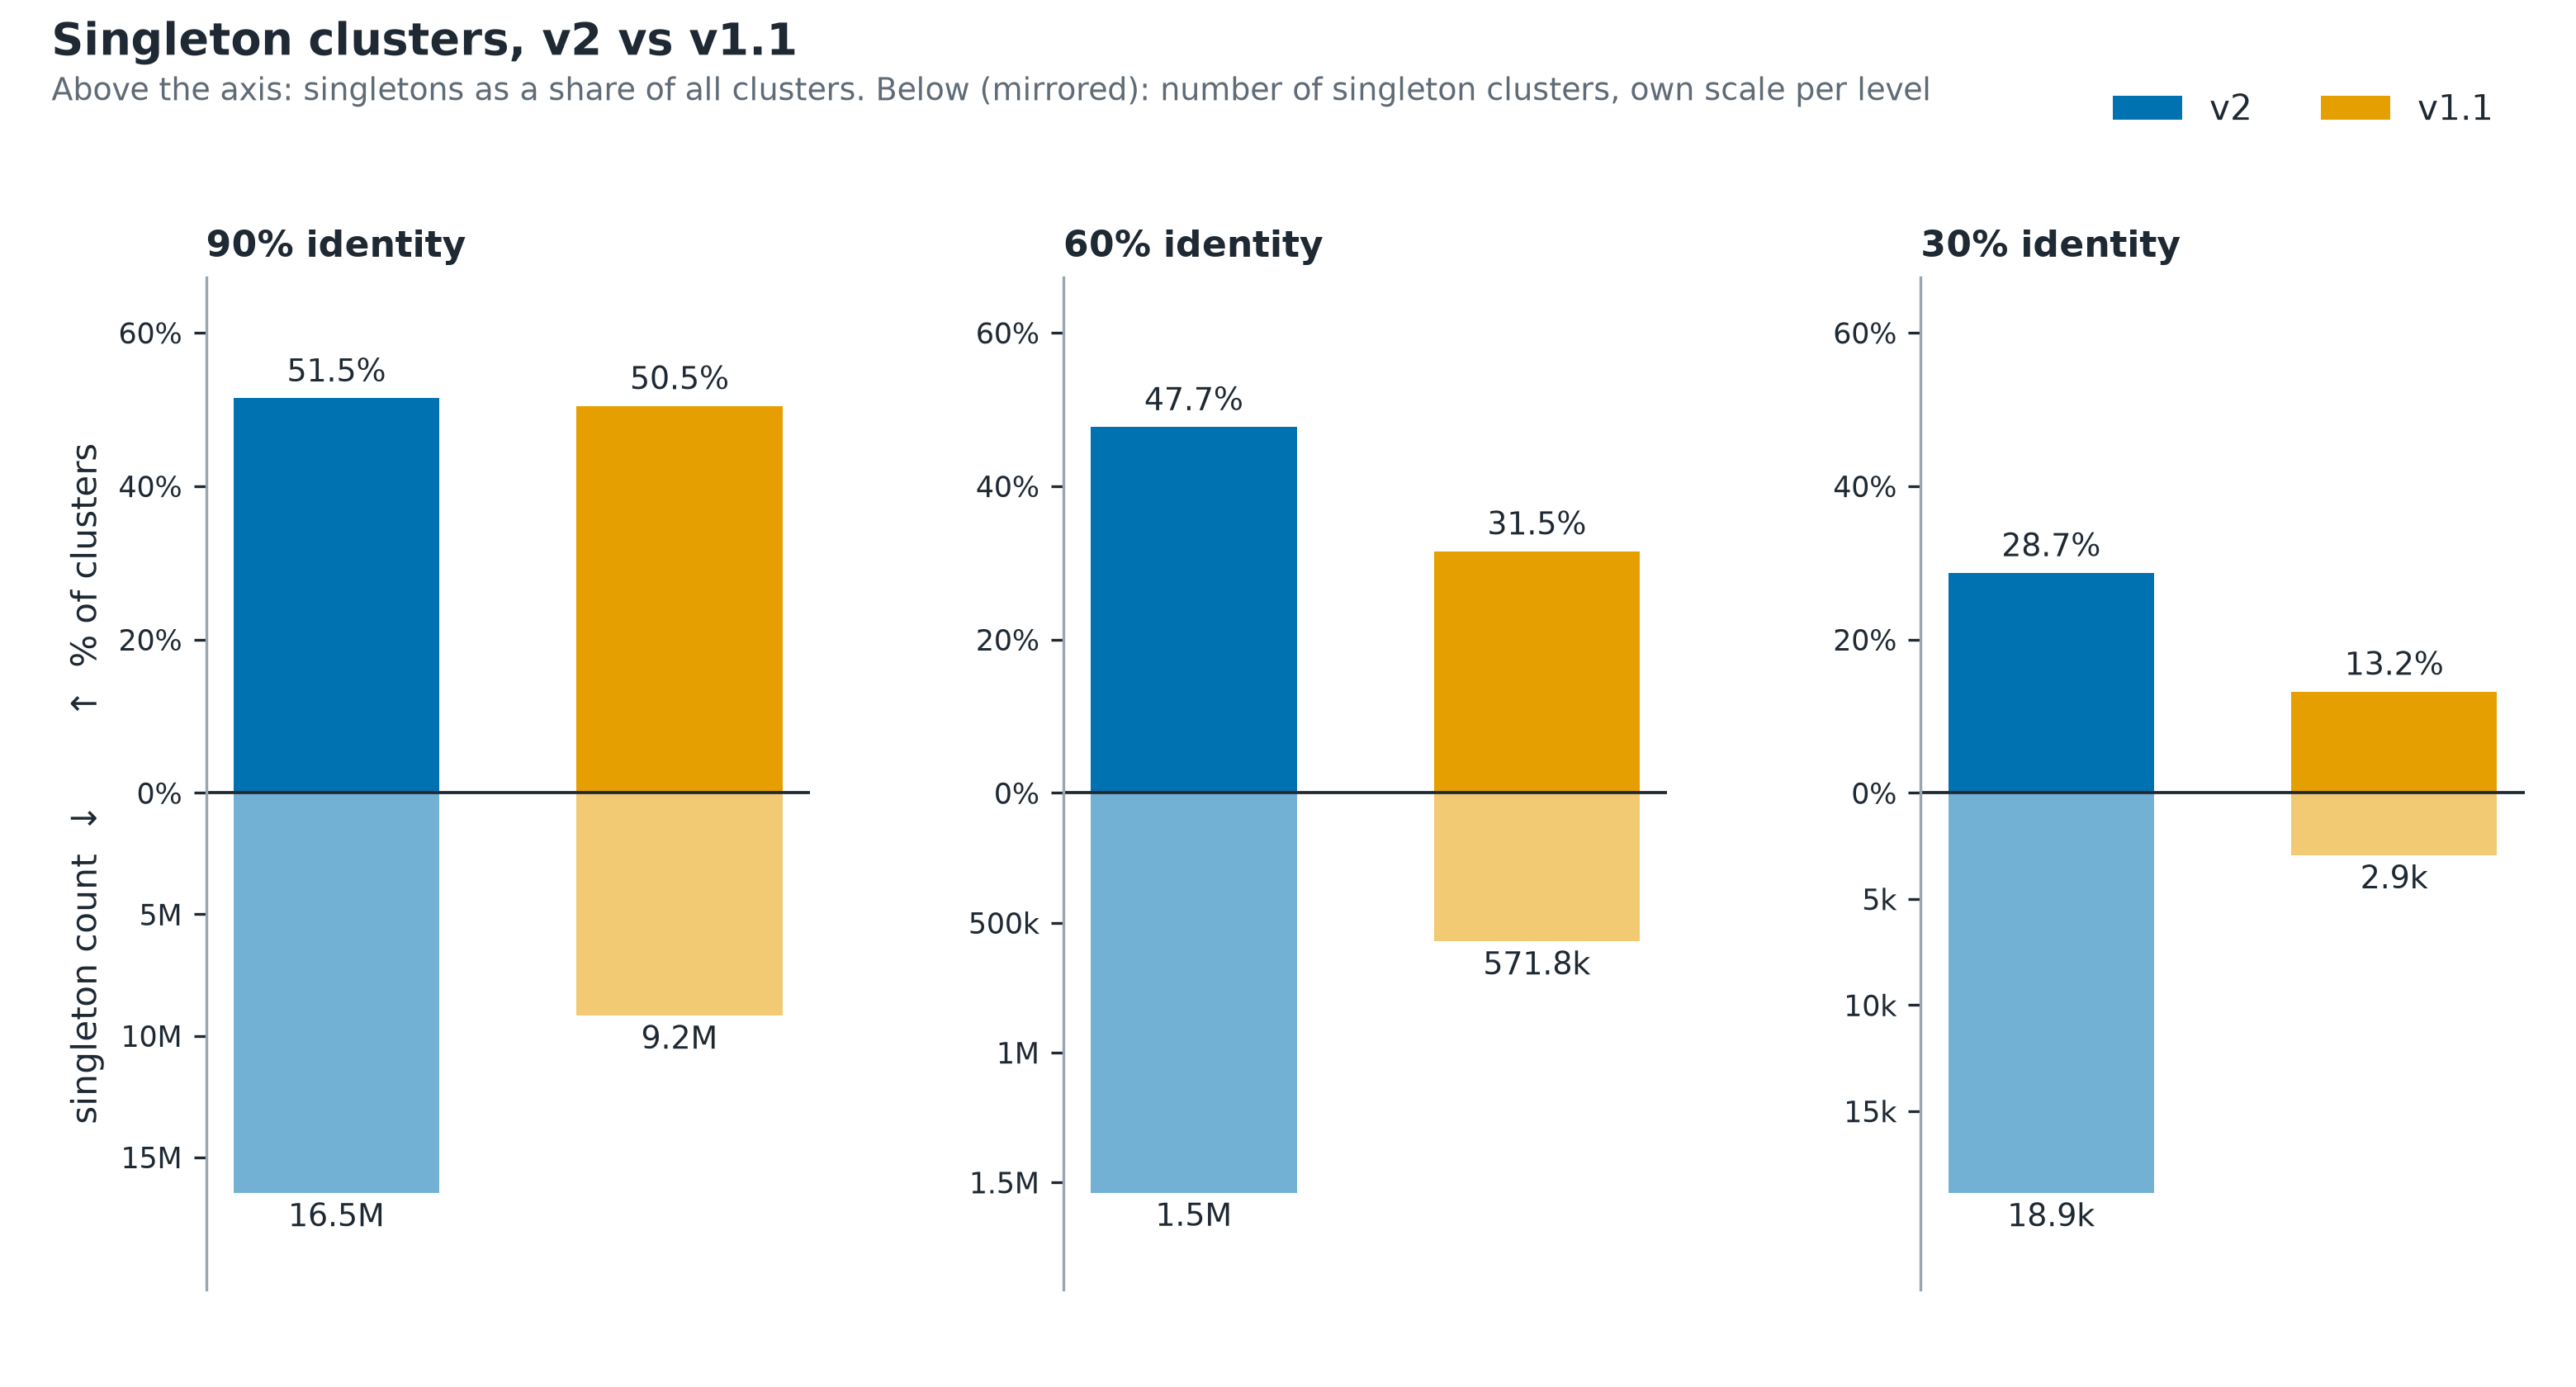

In [15]:
show('fig5_singletons_vs_v11', 900)

The singleton share matches v1.1 at 90 % (51.5 % vs 50.5 %) but not below it: 47.7 % vs 31.5 % at 60 % and 28.7 % vs 13.2 % at 30 %.
In both runs nearly all singletons are Logan sequences. v2 also has many more clusters than v1.1 at every level (1.8× at 90 %,
3.0× at 30 %), and the two runs differ in input and method, including full ORFs (v1.1) vs catalytic cores (v2); see
[`docs/caveats.md`](docs/caveats.md). v1.1 numbers: Benjamin's output, tabulated in `data/v11/`.

### Progress across runs

In [16]:
hist = pd.DataFrame([
    ['v1.1 (Benjamin; full ORFs, older input)',     18_172_960, 1_814_296,  22_235],
    ['Run 1: per component (own settings)',          30_453_501, 2_928_810, 167_232],
    ['Run 2: per CATH domain (own settings)',        None,       None,       77_524],
    ['v2 (unid pipeline), this notebook', int(tot.loc['L90', 'clusters']), int(tot.loc['L60', 'clusters']), int(tot.loc['L30', 'clusters'])],
], columns=['run', '90% clusters', '60% clusters', '30% clusters']).set_index('run')
hist.style.format('{:,.0f}', na_rep='n/a')

,90% clusters,60% clusters,30% clusters
run,,,
"v1.1 (Benjamin; full ORFs, older input)","18,172,960","1,814,296","22,235"
Run 1: per component (own settings),"30,453,501","2,928,810","167,232"
Run 2: per CATH domain (own settings),n/a,n/a,"77,524"
"v2 (unid pipeline), this notebook","32,022,716","3,230,662","65,769"


## 6. Who are the singletons?
Computed from the finished cluster files; outputs in `data/diagnostics/` and `data/fragmentation/`.

In [17]:
DIAG = os.path.join(DATA, 'diagnostics')
B = pd.read_csv(os.path.join(DIAG, 'lineage_by_class.tsv'), sep='\t')
RATE = pd.read_csv(os.path.join(DIAG, 'singleton_rate_by_source.tsv'), sep='\t')

### 6.1 Singleton rate by source

In [18]:
r = RATE[RATE.source != 'PL'].copy(); r['source'] = r['source'].map({'LG': 'Logan', 'NR': 'nr'}); r['level'] = r['level'].map(LV)
r = r.rename(columns={'v2_rate': 'v2 singleton %', 'v11_rate': 'v1.1 singleton %', 'v2_singletons': 'v2 singletons', 'v11_singletons': 'v1.1 singletons'})
r.set_index(['level', 'source'])[['v2 singletons', 'v2 singleton %', 'v1.1 singletons', 'v1.1 singleton %']].style.format(
    {'v2 singletons': '{:,}', 'v1.1 singletons': '{:,}', 'v2 singleton %': '{:.1f}', 'v1.1 singleton %': '{:.1f}'})

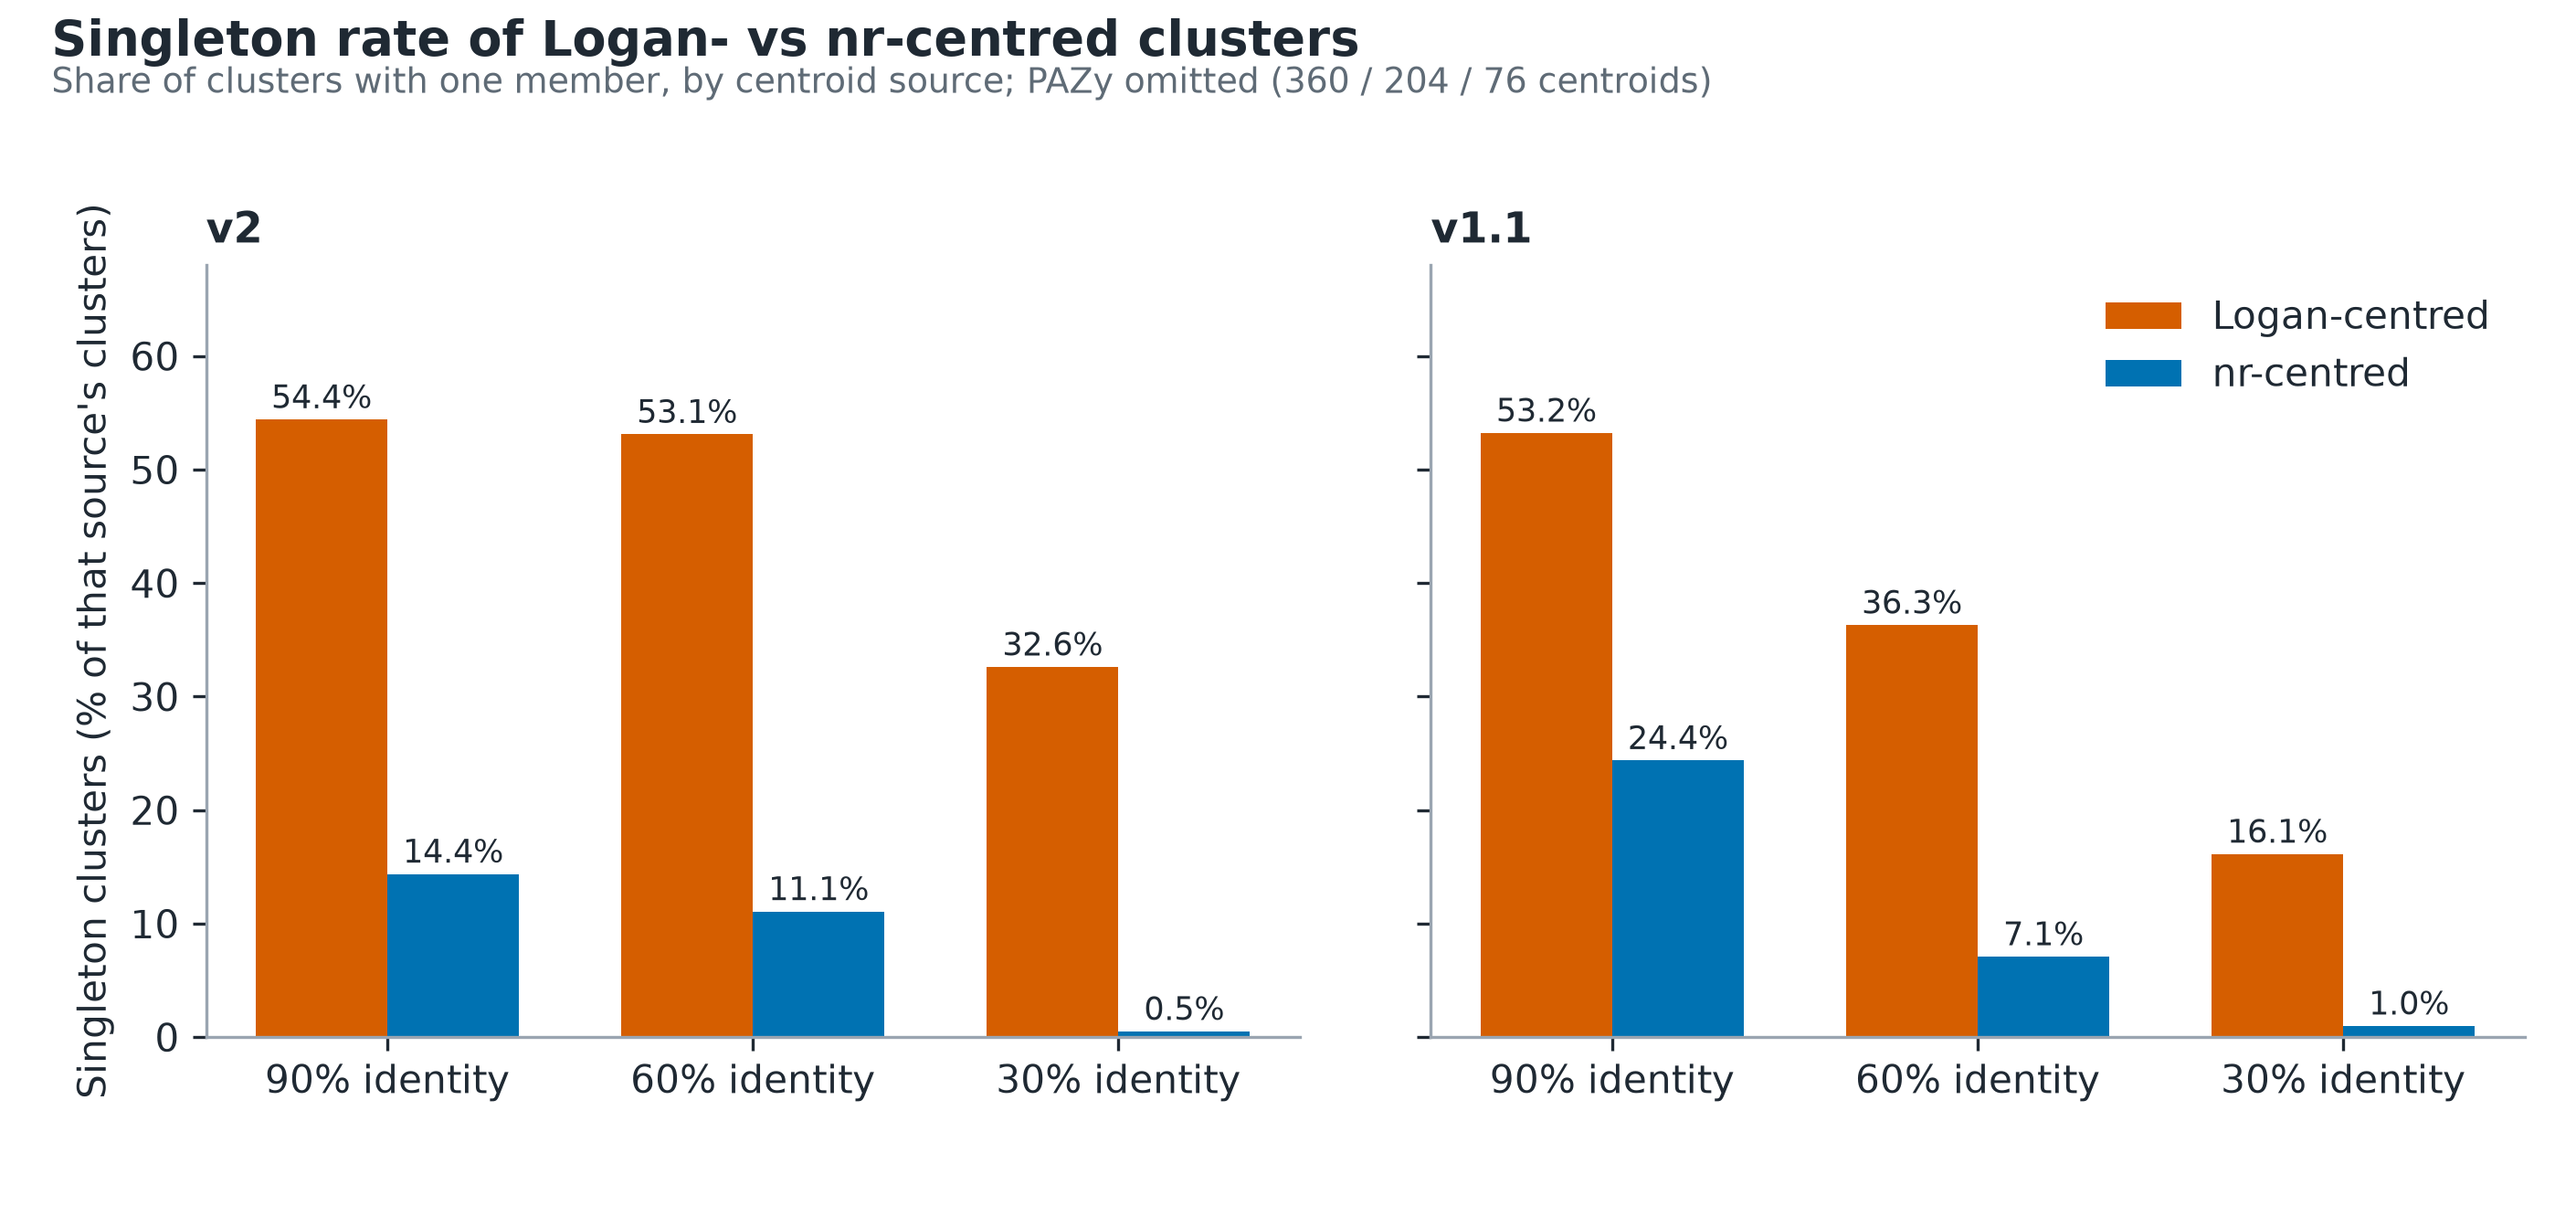

In [19]:
show('fig6_singleton_rate_by_source', 900)

Logan-centred clusters are singletons far more often than nr-centred ones in both runs. In v2 the Logan rate stays high from
90 % to 60 % (54.4 → 53.1 %) where v1.1's falls (53.2 → 36.3 %). Part of the nr/Logan contrast is built into the method: Logan
cores are mapped onto nr centroids, so an nr centroid rarely stays alone, while a Logan centroid can only collect other Logan cores.

### 6.2 How much sequence do the singletons hold?

In [20]:
tot_cores = B[B.level == 'L90']['cores'].sum()
x = B[B.singleton == 1].groupby('level')[['clusters', 'cores']].sum().loc[['L90', 'L60', 'L30']]
x['% of clusters'] = x['clusters'] / tot.loc[x.index, 'clusters'] * 100; x['% of all cores'] = x['cores'] / tot_cores * 100
x.index = [LV[i] for i in x.index]
x.rename(columns={'clusters': 'singleton clusters', 'cores': 'original cores inside them'}).style.format(
    {'singleton clusters': '{:,}', 'original cores inside them': '{:,}', '% of clusters': '{:.1f}', '% of all cores': '{:.3f}'})

,singleton clusters,original cores inside them,% of clusters,% of all cores
90%,"16,479,281","16,479,281",51.5,5.517
60%,"1,541,646","4,169,815",47.7,1.396
30%,"18,866","161,801",28.7,0.054


"Original cores inside them" follows each centroid back down the hierarchy: a 30 % singleton holds every core of the 60 % and
90 % clusters beneath it. At 30 % the singletons are 28.7 % of clusters but hold 0.054 % of the 298.7 M cores.

### 6.3 Does the fragmented nature of Logan sequences make them harder to cluster?
Two things must hold: Logan cores are fragmented compared with nr, and short sequences end up as singletons more often than long
ones **within the same source**, so the result is not just "Logan vs nr".

In [21]:
FR = os.path.join(DATA, 'fragmentation')
display(pd.read_csv(os.path.join(FR, 'core_length_stats_L90.tsv'), sep='\t', index_col=0).style.format(
    {'cores': '{:,.0f}', 'mean length (aa)': '{:.0f}', '25th percentile': '{:.0f}', 'median': '{:.0f}', '75th percentile': '{:.0f}', '% shorter than 150 aa': '{:.1f}'}))

,cores,mean length (aa),25th percentile,median,75th percentile,% shorter than 150 aa
Logan,"291,922,243",212,138,213,262,28.4
nr,"6,764,617",317,246,293,391,0.7


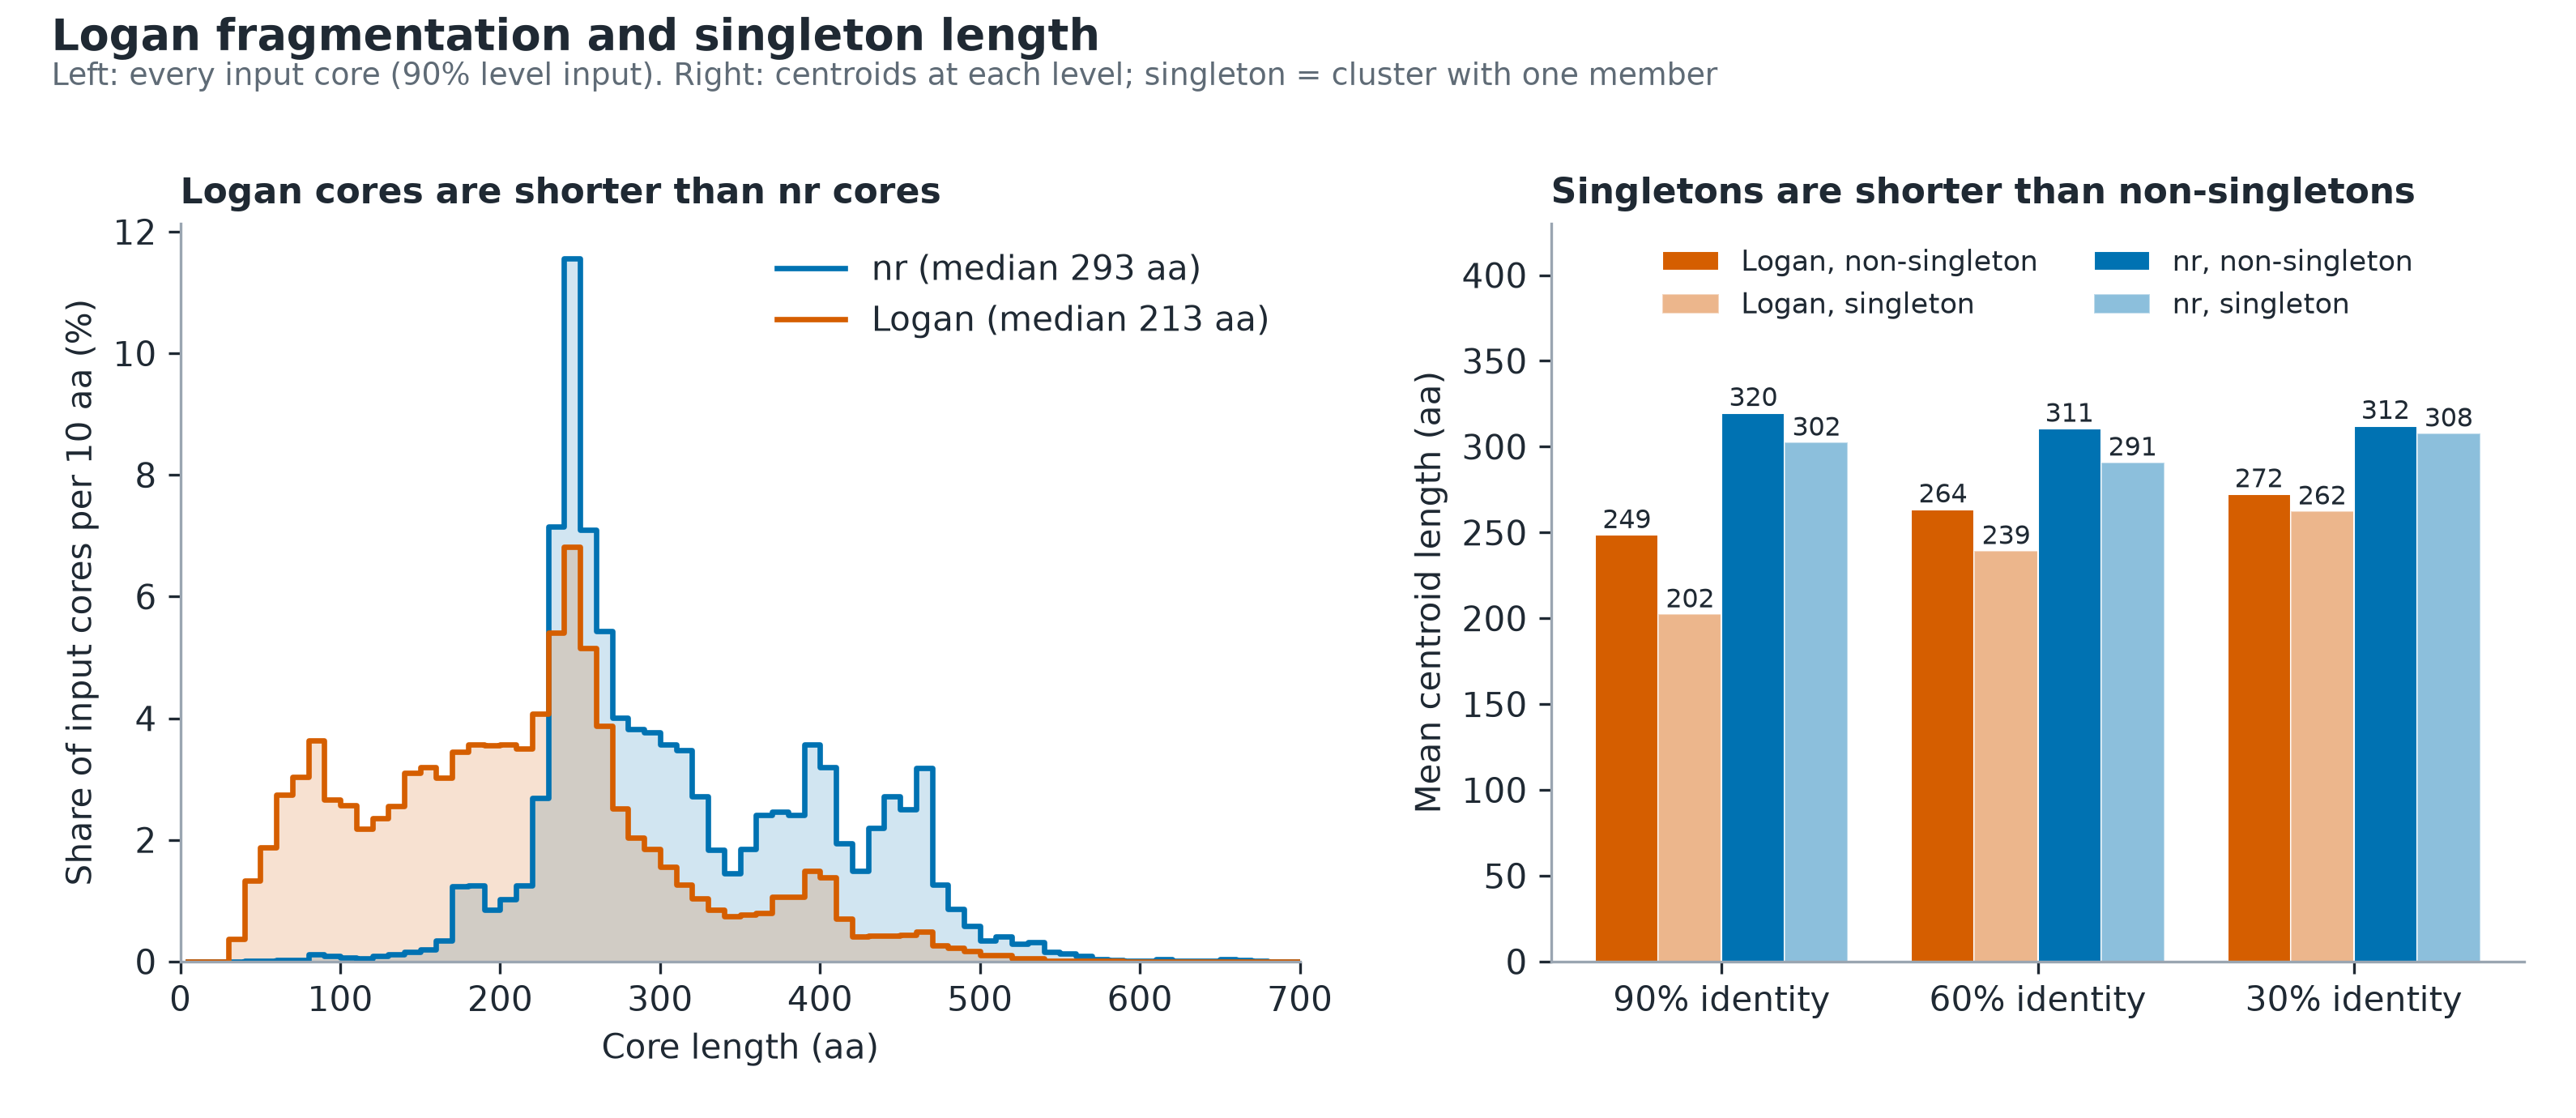

In [22]:
show('fig7_logan_fragmentation', 940)

- **Logan cores are shorter.** Median 213 aa against 293 aa for nr; 28.4 % of Logan cores are shorter than 150 aa, against 0.7 % of nr.
  It is not just a difference in domain mix: measured against each domain's own median nr core length, 43.1 % of Logan cores are
  shorter than 0.7× that length, against 2.6 % of nr. It varies by domain: most domains show it strongly, but in peptidase S8/S53,
  SGNH hydrolase, GH deacetylase and trypsin-like, Logan cores are not shorter.
- **Singletons are shorter than non-singletons, in both sources.** At 90 % the mean Logan singleton centroid is 202 aa against 249 aa for
  non-singletons; for nr, 302 vs 320 aa. Under the 90 % member-coverage rule a short centroid cannot take in longer sequences.
- **The effect fades toward 30 %** (Logan 262 vs 272 aa), because by then the centroids are mostly full-length sequences chosen at 90 % and 60 %.
- **nr is not a clean baseline for raw singleton rates.** Logan cores are mapped onto nr centroids, so nr centroids rarely stay alone by
  construction. The comparable result is the length difference, which has the same direction in both sources.
- **This does not explain the gap to v1.1.** Fragmentation is strongest at 90 %, where v2 and v1.1 agree, and v1.1 clustered full ORFs.

## 7. Conclusions and open questions

1. The clustering is valid: one cluster per core, one cluster per centroid, exact nesting (section 3).
2. 298.7 M cores → 32.0 M (90 %) → 3.23 M (60 %) → 65,769 (30 %) clusters; Logan provides 87–93 % of centroids at every level.
3. Singletons are nearly all Logan-centred and hold almost none of the sequence. Logan cores are often fragments, and singletons are
   shorter than non-singletons in both Logan and nr, most clearly at 90 %.
4. v2 has more singletons and far more clusters than v1.1 below 90 %. The runs differ in input and method (full ORFs vs cores among
   them), so the cause cannot be isolated with these data.

Open: why trypsin-like has so many superfamilies; why v2 has ~3× v1.1's superfamilies. Details and the other caveats are in
[`docs/caveats.md`](docs/caveats.md).

## Supplementary
### S1. Clusters vs sequences by centroid source
For each level: share of clusters, and share of all cores beneath them, coloured by the source of the cluster's centroid. Note the
"sequences" bar colours each core by its cluster's centroid, not by the core's own source (97.7 % of all cores are Logan).

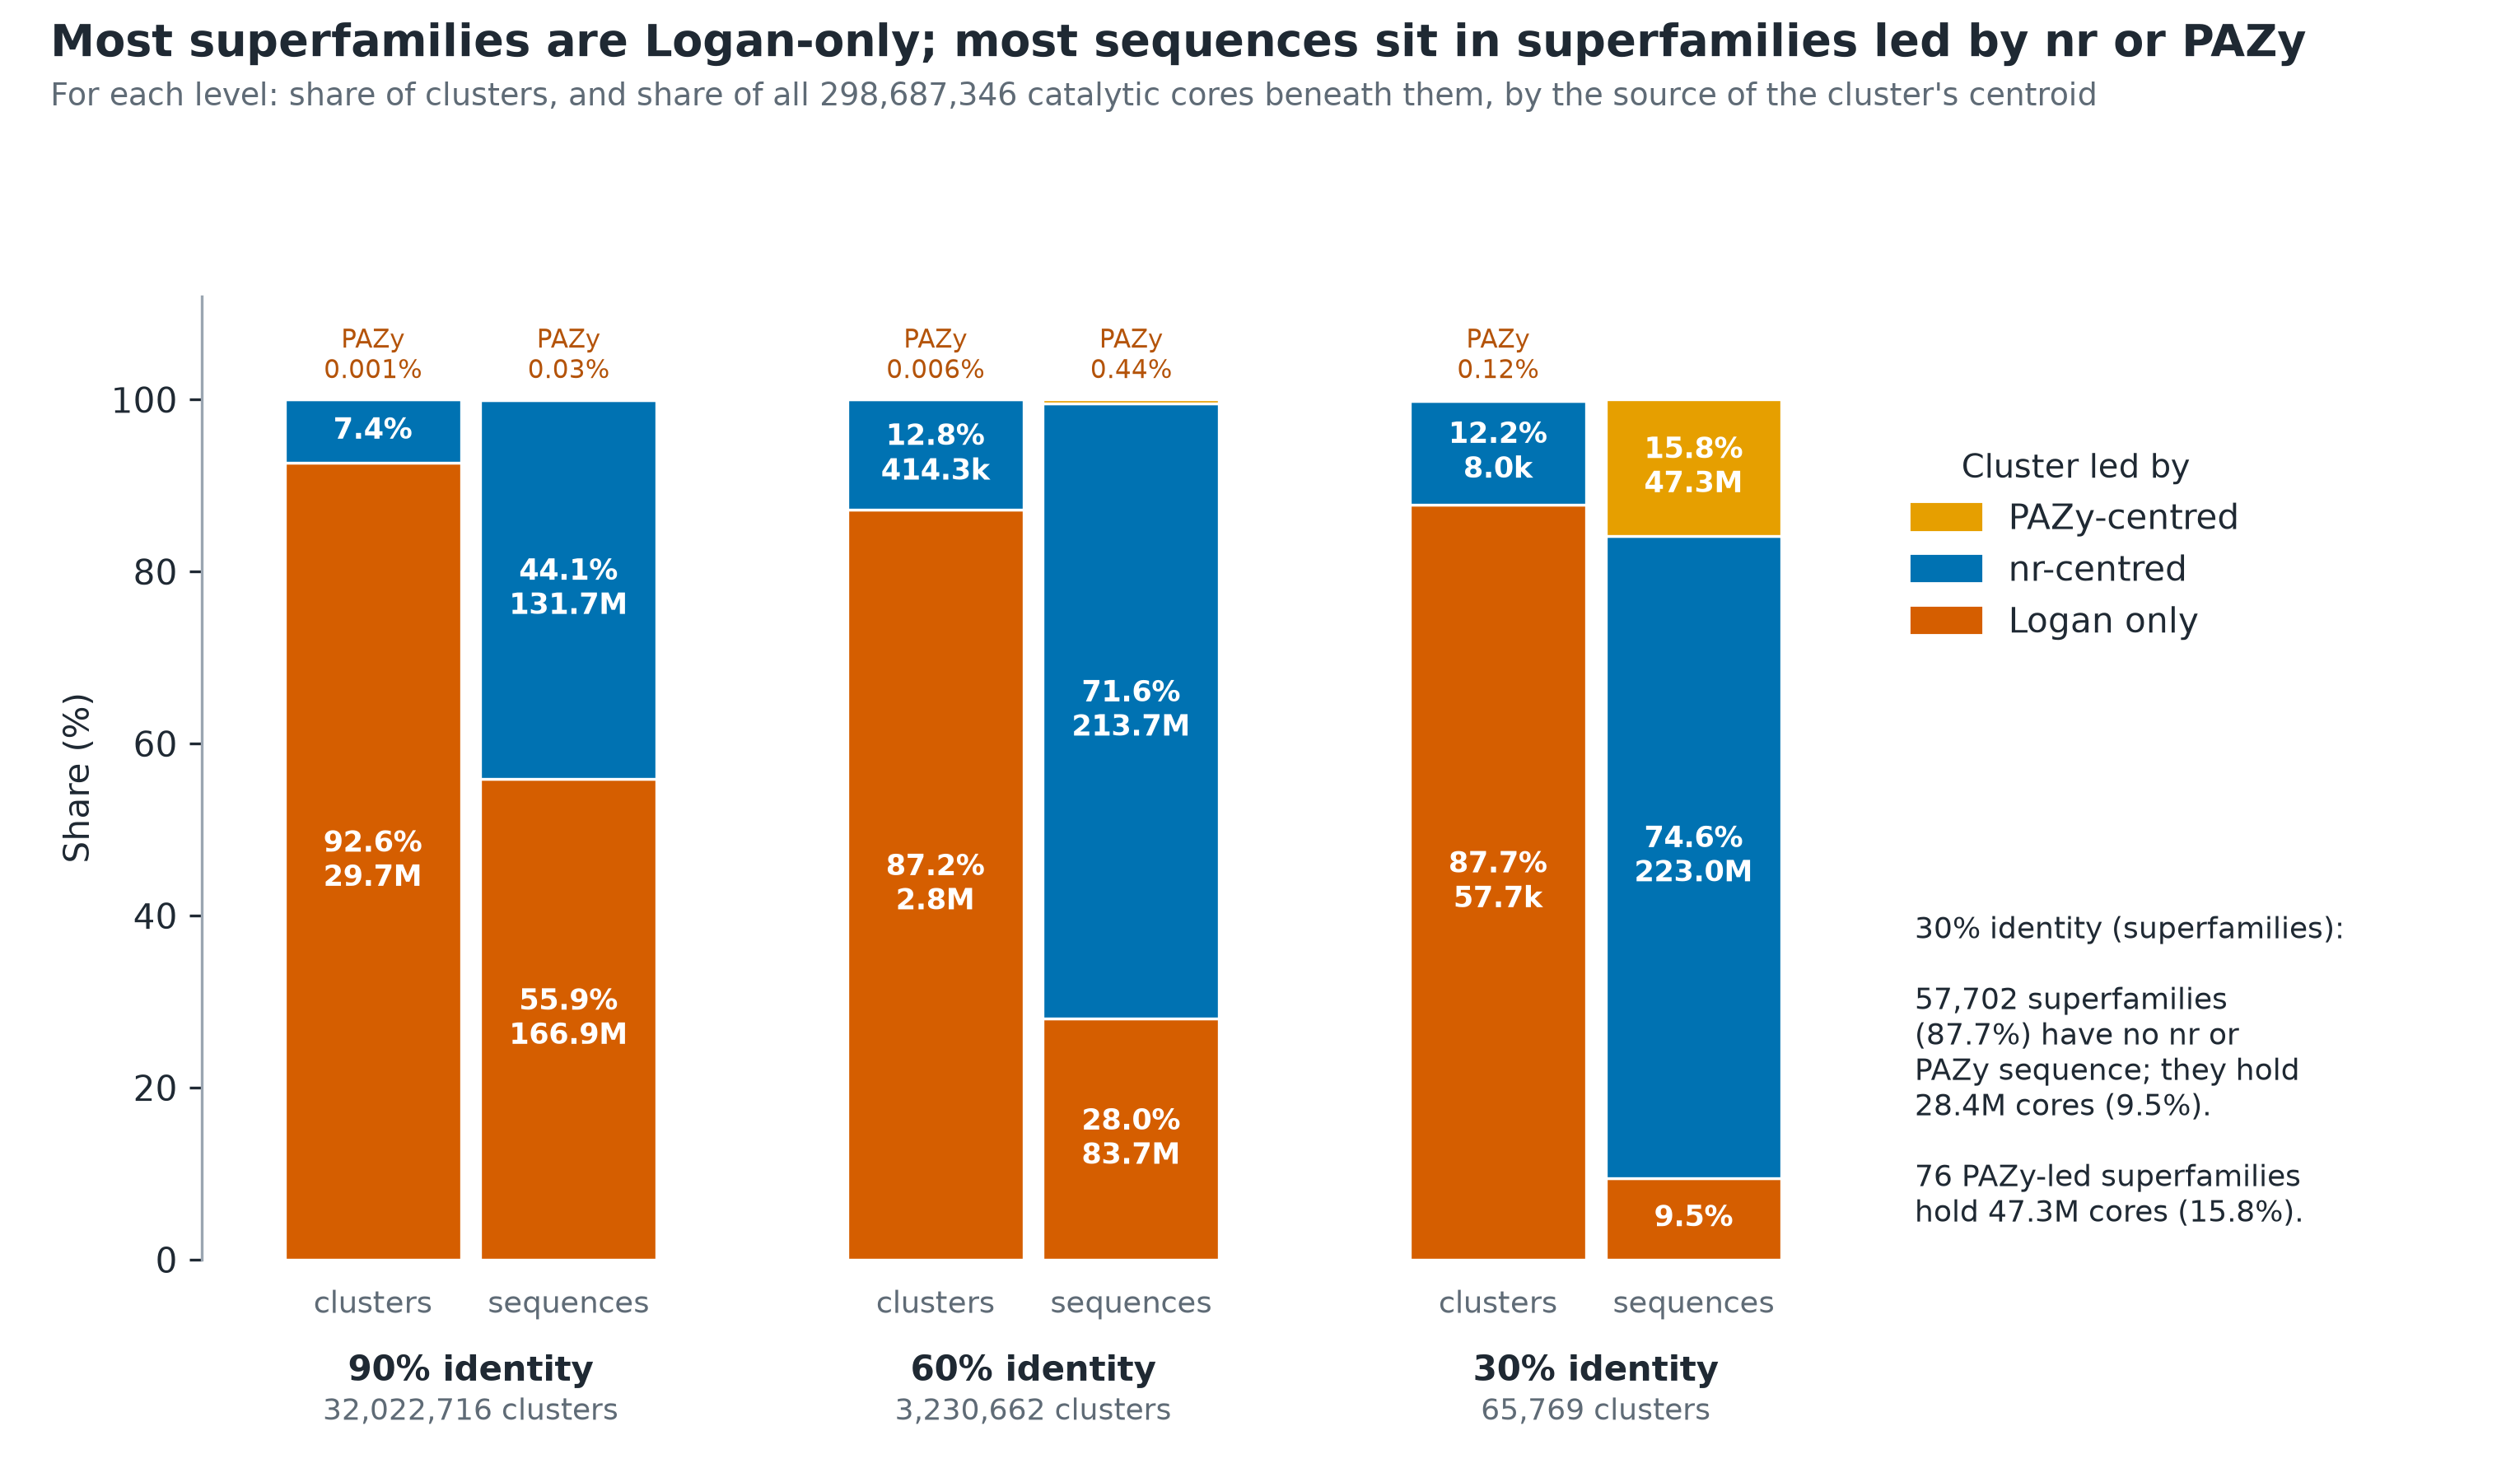

In [23]:
show('figS1_clusters_vs_sequences', 900)

In [24]:
s1 = pd.read_csv(os.path.join(DATA, 'figureS1_clusters_vs_cores.tsv'), sep='\t')
s1['level'] = s1['level'].map(LV); s1['source'] = s1['source'].map({'LG': 'Logan only', 'NR': 'nr-centred', 'PL': 'PAZy-centred'})
s1.set_index(['level', 'source']).rename(columns={'pct_clusters': '% of clusters', 'pct_cores': '% of cores'}).style.format(
    {'clusters': '{:,}', 'cores': '{:,}', '% of clusters': '{:.3g}', '% of cores': '{:.3g}'})